# Final 2 – Analyse, modellen en deployment: hoeveel Citi Bikes vertrekken er per zone per uur?

| | |
|---|---|
| **Auteur(s)** | Kobe Vandenberk |
| **Wat** | Alles na de cleaning, in één notebook: wat de data vertelt (EDA), twee getoetste hypotheses, de vergelijking van alle technieken op 2024, het definitieve model op alle data, de foutenanalyse en de deployment. Bij elke poging: **waarom** we het probeerden, **wat** het opleverde, en **waarom we er wel of niet mee verder gingen**. Alle code staat in dit notebook zelf; er is geen ander bestand nodig. |
| **Input** | de tabellen uit `01_cleaning.ipynb`: `data/model_table.parquet` en `data/zones.json` (alle jaren), `data/2024/*` (studie op 2024) |
| **Output** | `models/searches/*` (resultaten van de zoektochten), `models/best_params.json`, `deploy/citi_bike_demand/model.pkl` (het model voor de API) |
| **GenAI** | Code en tekst opgesteld met hulp van Claude; keuzes en resultaten nagekeken door Kobe. |

## Leeswijzer
| Deel | Vraag | Data |
|---|---|---|
| **A. EDA** | Wanneer en waar fietst New York, en wat bepaalt dat? | alle jaren en 2024 |
| **B. Hypotheses** | Is er een echt, statistisch onderbouwd patroon om te voorspellen? | 2024 |
| **C. Modelselectie** | Welke techniek werkt het best: baseline, Poisson-GLM, random forest, PyCaret (AutoML), gradient boosting, lags? | 2024 |
| **D. Definitief model** | Wordt de beste techniek beter met 13 jaar data? Welke kenmerken zijn nodig? | alle jaren |
| **E. Foutenanalyse** | Waar vergist het definitieve model zich, en waarom? | alle jaren |
| **F. Deployment** | Hoe komt het model bij de gebruiker? | |
| **G. Conclusie** | Wat werkte, wat niet, en waarom? | |

**Waarom eerst op 2024 en daarna op alle data?** Op één jaar (263.000 zone-uren) duurt een model trainen seconden, op alle jaren (2,8 miljoen zone-uren) minuten. We vergeleken de technieken daarom grondig op 2024 en trainden alleen de winnaar op alle data.

### Zoektochten opnieuw uitvoeren of niet?
Het zoeken naar hyperparameters (grid search, randomized search, PyCaret) duurt samen enkele uren. Elke zoektocht bewaart zijn volledige resultaat in `models/searches/`. Met `RUN_SEARCHES = False` (standaard) gebruikt dit notebook die bewaarde resultaten als ze bestaan, en voert het de zoektocht anders zelf uit; alle andere modellen worden altijd opnieuw getraind en gemeten. Met `RUN_SEARCHES = True` wordt elke zoektocht opnieuw gedaan. (Voor PyCaret is de omgeving met Python 3.11 nodig, zie `requirements.txt`.)

In [1]:
RUN_SEARCHES = False

## 0. Imports en data

In [2]:
%matplotlib inline
import json
import os
from datetime import datetime, timezone
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from pandas.tseries.holiday import USFederalHolidayCalendar
from scipy import stats
from scipy.stats import loguniform, randint, uniform
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import PoissonRegressor
from sklearn.metrics import make_scorer, mean_absolute_error, mean_poisson_deviance, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, GroupKFold, RandomizedSearchCV, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, SplineTransformer, StandardScaler

KOBE = Path.cwd().parent                          # citi_bike/Kobe (dit notebook staat in citi_bike/Kobe/Final)
DATA_DIR = KOBE / "data"
DATA_2024 = DATA_DIR / "2024"
MODEL_DIR = KOBE / "models"
SEARCH_DIR = MODEL_DIR / "searches"
DEPLOY_MODEL = KOBE.parent.parent / "deploy" / "citi_bike_demand" / "model.pkl"
SEED = 42
os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(max(1, (os.cpu_count() or 2) - 1)))

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
GREEN, ORANGE, INK, BLUE = "#2f6f4f", "#c47f00", "#17201b", "#3b6fb6"
pd.set_option("display.max_columns", 30)

# Studie op 2024 (uit 01_cleaning §17)
t24 = pd.read_parquet(DATA_2024 / "model_table.parquet")
sh24 = pd.read_parquet(DATA_2024 / "station_hour.parquet")
st24 = pd.read_parquet(DATA_2024 / "station_zones.parquet")          # publieke stations van 2024, met zone
zones24 = pd.DataFrame(json.loads((DATA_2024 / "zones.json").read_text(encoding="utf-8"))).set_index("zone")
# Alle data (uit 01_cleaning §13-18)
table = pd.read_parquet(DATA_DIR / "model_table.parquet")
zones = pd.DataFrame(json.loads((DATA_DIR / "zones.json").read_text(encoding="utf-8"))).set_index("zone")
print(f"2024: {len(t24):,} zone-uren, {t24['trips'].sum():,} vertrekken | alle data: {len(table):,} zone-uren "
      f"({table['time'].min():%Y-%m} t/m {table['time'].max():%Y-%m}), {table['trips'].sum():,} vertrekken")

2024: 263,520 zone-uren, 44,269,890 vertrekken | alle data: 2,818,992 zone-uren (2013-06 t/m 2026-09), 328,688,926 vertrekken


---
# Deel A – EDA: wat bepaalt de vraag?
Het doel van de EDA is niet een verzameling grafieken, maar de vraag: **welke informatie heeft een model nodig om de vraag te voorspellen?** Elke vaststelling eindigt daarom in een gevolg voor het model.

## A1. Dertien jaar groei

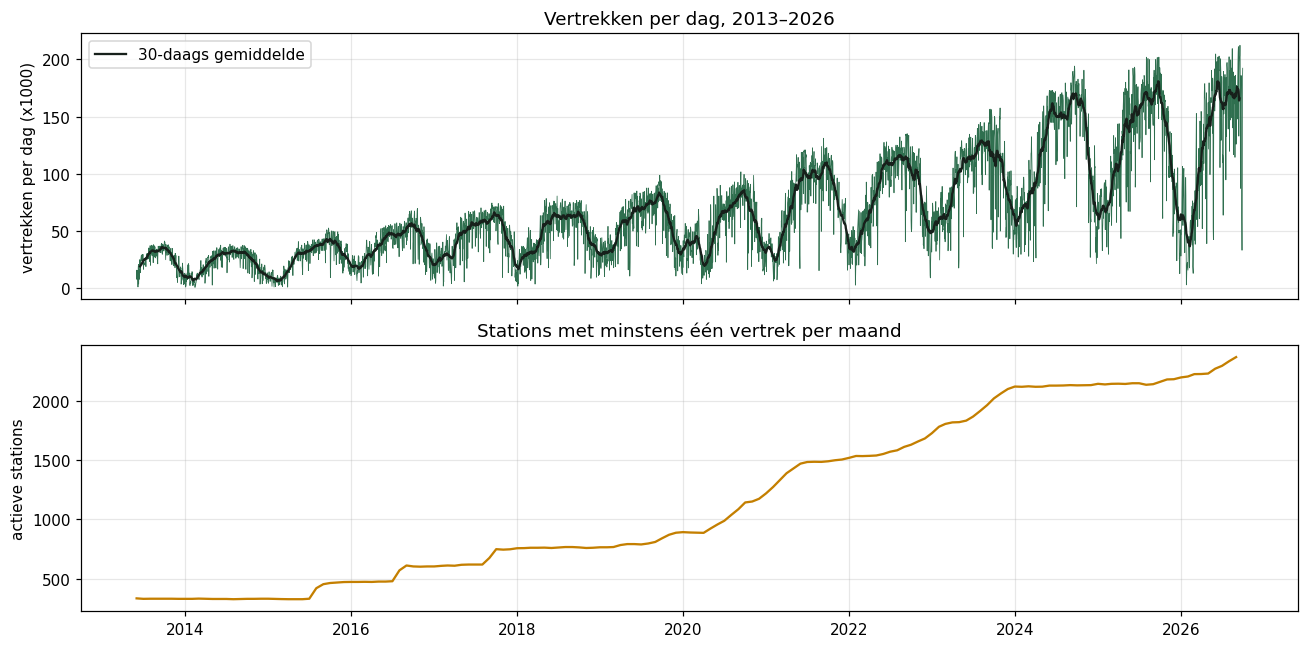

time,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
trips,5613171.0,8081216.0,9937954.0,13844352.0,16362735.0,17544527.0,20551820.0,19561911.0,27128930.0,29837939.0,35088143.0,44270097.0,45745677.0,35120454.0
groei %,NaN,44.0,23.0,39.3,18.2,7.2,17.1,-4.8,38.7,10.0,17.6,26.2,3.3,-23.2
% member,83.9,90.2,86.8,88.8,89.1,89.0,86.0,77.0,73.2,77.9,81.2,80.7,82.6,81.9
% e-bike,0.0,0.0,0.0,0.0,0.0,0.0,0.0,14.1,31.8,39.3,50.1,66.1,70.4,72.6


In [3]:
daily_all = table.groupby(table["time"].dt.normalize())["trips"].sum()
active_month = table.groupby([table["time"].dt.to_period("M"), "zone"])["active_stations"].first().groupby(level=0).sum()
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(daily_all.index, daily_all / 1000, color=GREEN, lw=.5)
axes[0].plot(daily_all.rolling(30, center=True).mean() / 1000, color=INK, lw=1.5, label="30-daags gemiddelde")
axes[0].set(ylabel="vertrekken per dag (x1000)", title="Vertrekken per dag, 2013–2026"); axes[0].legend()
axes[1].plot(active_month.index.to_timestamp(), active_month.values, color=ORANGE)
axes[1].set(ylabel="actieve stations", title="Stations met minstens één vertrek per maand")
plt.tight_layout()
plt.show()
yearly = table.groupby(table["time"].dt.year)[["trips", "members", "electric"]].sum()
(yearly.assign(**{"groei %": yearly["trips"].pct_change() * 100, "% member": yearly["members"] / yearly["trips"] * 100,
                  "% e-bike": yearly["electric"] / yearly["trips"] * 100})
       [["trips", "groei %", "% member", "% e-bike"]].round(1).T)

**Vaststelling:**
- de vraag groeit van ± 35.000 vertrekken per dag in de zomer van 2013 naar ± 170.000 in 2025–2026, altijd met hetzelfde **seizoenspatroon** (winterdal, zomer- en vroege-herfstpiek); 2013 en 2026 zijn onvolledige jaren;
- het netwerk groeit in **sprongen**: 330 stations (2013), ± 750 (2018), ± 1.400 (2021), ± 2.100 (2024) en ± 2.300 (2026). Elke sprong is een uitbreiding naar nieuwe buurten;
- **corona** (voorjaar 2020): een korte dip, daarna de snelste groei ooit (2021: +39%), met meer **casual** riders (14% in 2019 → 27% in 2021) en de opkomst van **e-bikes** (0% → 73%).

**Gevolg voor het model:** een model dat alleen kalender en weer kent, begrijpt de groei niet. Het krijgt daarom het **jaar** en het **aantal actieve stations** in de zone als kenmerken (deel D).

## A2. Seizoen en temperatuur (2024)

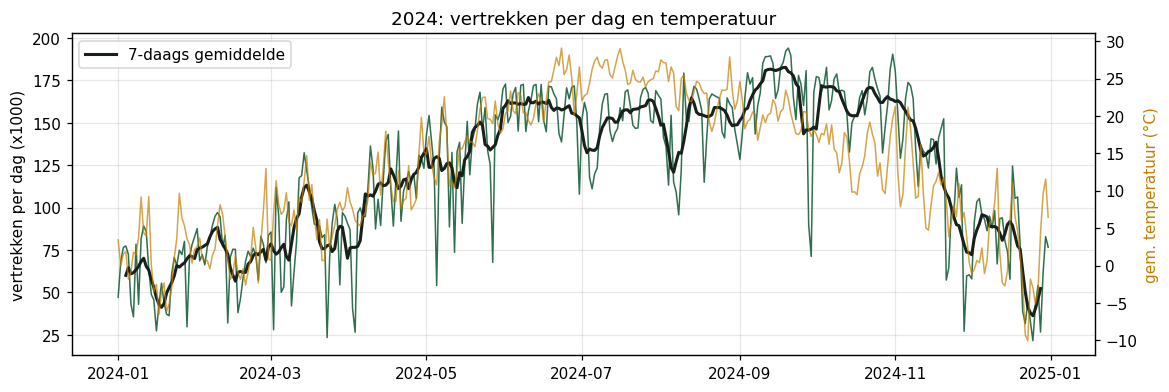

Spearman dagtotaal ~ temperatuur: 0.77


,trips,temperature_c,precipitation_mm
time,,,
2024-12-25,21562,-3.0,0.0
2024-03-23,23396,6.2,63.2
2024-04-03,26526,6.1,25.0
2024-12-28,26708,4.4,5.5
2024-11-28,27089,7.1,17.9


In [4]:
city24 = t24.groupby("time")[["trips", "members"]].sum().reset_index().merge(
    t24.drop_duplicates("time")[["time", "temperature_c", "precipitation_mm", "wind_kmh", "snowfall_cm"]], on="time")
day24 = city24.set_index("time").resample("D").agg({"trips": "sum", "temperature_c": "mean", "precipitation_mm": "sum"})
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(day24.index, day24["trips"] / 1000, color=GREEN, lw=1)
ax.plot(day24["trips"].rolling(7, center=True).mean() / 1000, color=INK, lw=2, label="7-daags gemiddelde")
ax.set(ylabel="vertrekken per dag (x1000)", title="2024: vertrekken per dag en temperatuur")
ax2 = ax.twinx(); ax2.plot(day24.index, day24["temperature_c"], color=ORANGE, lw=1, alpha=.7)
ax2.set_ylabel("gem. temperatuur (°C)", color=ORANGE); ax2.grid(False)
ax.legend(loc="upper left")
plt.show()
print("Spearman dagtotaal ~ temperatuur:", round(day24["trips"].corr(day24["temperature_c"], method="spearman"), 2))
day24.nsmallest(5, "trips").round(1)

**Vaststelling:**
- een duidelijk **seizoenspatroon**: rond 50.000 vertrekken per dag in januari, 150.000 tot 190.000 van juni tot oktober. Het dagtotaal volgt de temperatuur (Spearman ρ = 0,77; *Spearman* meet of twee reeksen samen stijgen en dalen, ook als het verband niet lineair is);
- binnen elke week zie je **diepe dalen**, bijna altijd regendagen: de rustigste dagen buiten de kerstperiode zijn 23 maart (63 mm regen) en 3 april (25 mm). Kerstmis is de rustigste dag van het jaar;
- de piek ligt in **september–oktober**, niet in juli: na de zomervakantie fietsen forenzen en studenten weer, terwijl het nog warm is.

**Gevolg:** temperatuur, neerslag, maand en feestdagen moeten in het model.

## A3. Het dagritme, en wat regen ermee doet (2024)

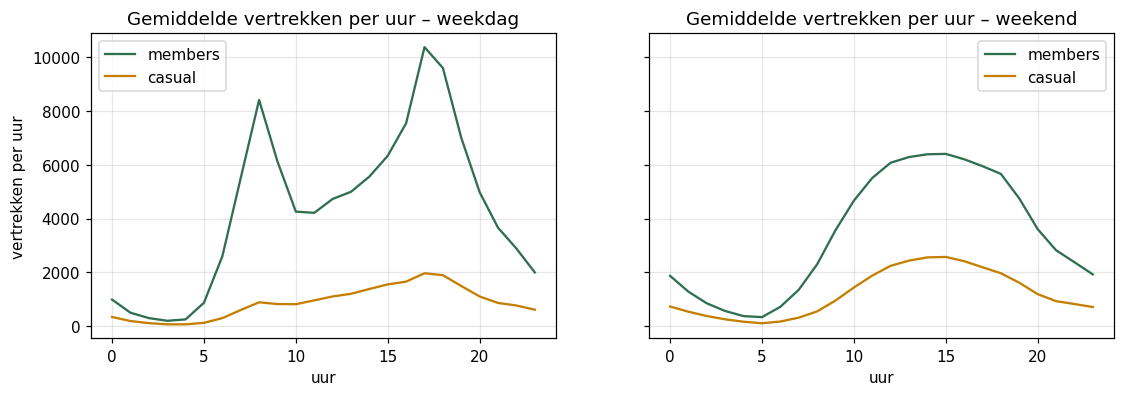

In [5]:
city24["hour"] = city24["time"].dt.hour
city24["daytype"] = np.where(city24["time"].dt.dayofweek >= 5, "weekend", "weekdag")
city24["casual"] = city24["trips"] - city24["members"]
profile = city24.groupby(["daytype", "hour"])[["members", "casual"]].mean()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, daytype in zip(axes, ["weekdag", "weekend"]):
    profile.loc[daytype].plot(ax=ax, color=[GREEN, ORANGE])
    ax.set(title=f"Gemiddelde vertrekken per uur – {daytype}", xlabel="uur", ylabel="vertrekken per uur")
plt.show()

**Vaststelling:** dit is het belangrijkste patroon in de data.
- **Weekdag**: members hebben twee pieken, om **8u** en (nog hoger) om **17u**: woon-werkverkeer. Casual riders fietsen vooral in de namiddag, zonder ochtendpiek.
- **Weekend**: geen spits, maar één brede bult van 10u tot 19u: vrijetijdsfietsen, ook bij members.

**Gevolg:** het uur alleen volstaat niet; het model moet **uur × weekdag/weekend** combineren (8u op maandag is iets anders dan 8u op zondag). In deel B toetsen we dit.

**Een eerste blik op regen:** zelfde uur, zelfde daltype, droog (0 mm) tegenover nat (≥ 0,5 mm per uur).

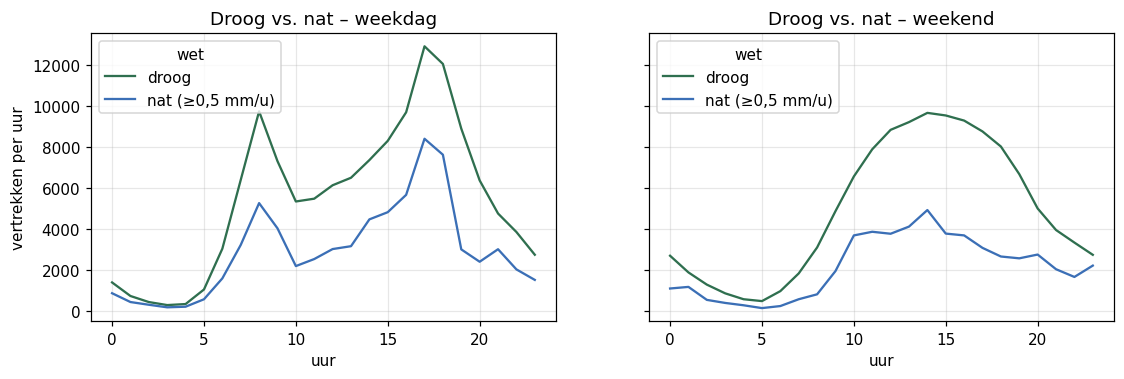

Uren per klasse: {'droog': 7504, 'motregen': 715, 'nat (≥0,5 mm/u)': 565}


In [6]:
city24["wet"] = np.where(city24["precipitation_mm"] >= 0.5, "nat (≥0,5 mm/u)", np.where(city24["precipitation_mm"] == 0, "droog", "motregen"))
rain = city24[city24["wet"] != "motregen"].groupby(["daytype", "hour", "wet"])["trips"].mean().unstack()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True)
for ax, daytype in zip(axes, ["weekdag", "weekend"]):
    rain.loc[daytype].plot(ax=ax, color=[GREEN, BLUE])
    ax.set(title=f"Droog vs. nat – {daytype}", xlabel="uur", ylabel="vertrekken per uur")
plt.show()
print("Uren per klasse:", city24["wet"].value_counts().to_dict())

**Vaststelling:** bij regen ligt de curve op elk uur duidelijk lager: op weekdagen ongeveer een derde, in het weekend zelfs meer dan de helft. Het weekendverkeer (vrije tijd) is gevoeliger voor regen dan het woon-werkverkeer: wie naar het werk moet, gaat toch.

Let op, dit is nog geen bewijs: misschien regent het vaker in de koude maanden (dan zou een deel van het verschil "winter" zijn). In B1 vergelijken we daarom alleen uren die verder gelijk zijn.

## A4. Waar? Stationsprofielen (unsupervised learning)
De zones (KMeans op locatie, zie `01_cleaning` §11) zeggen *waar*. Maar gedragen alle buurten zich hetzelfde? We clusteren de stations een tweede keer met **KMeans**, nu op hun **gedrag**: per station het aandeel van zijn vertrekken per uur, apart voor weekdagen en weekend (48 getallen die samen 1 zijn). Zo vergelijken we de *vorm* van het dagpatroon, los van hoe druk een station is. We nemen stations met minstens 2.000 vertrekken in 2024, anders is het profiel te ruizig.

Inertia per k: {2: 6.238, 3: 5.322, 4: 4.913, 5: 4.584, 6: 4.335, 7: 4.124, 8: 3.971}


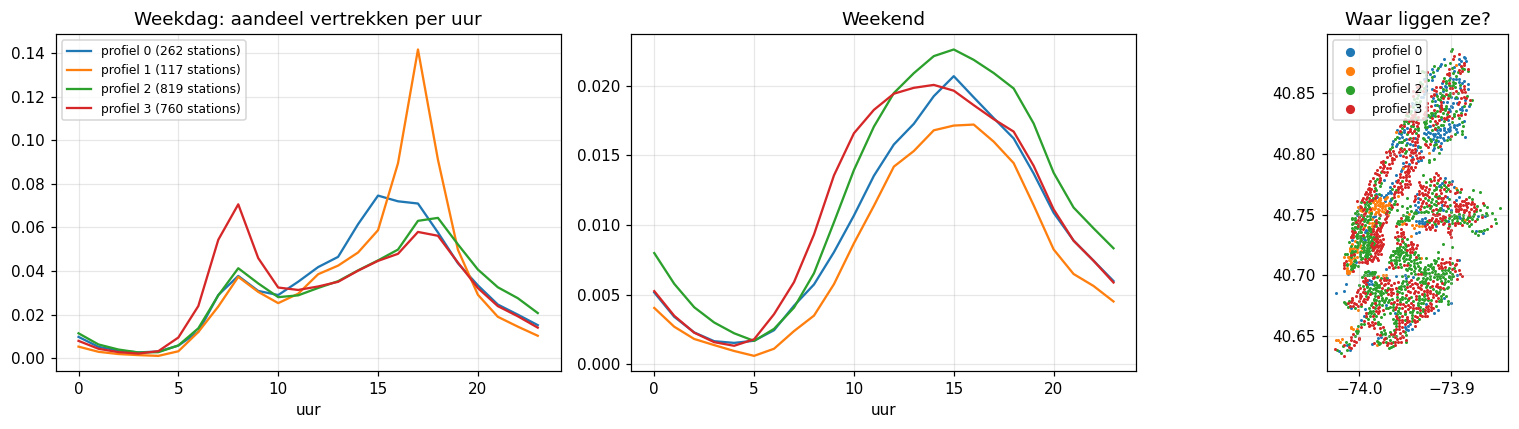

,stations,piekuur weekdag,aandeel in dat uur %
profiel,,,
0,262,15,7.5
1,117,17,14.2
2,819,18,6.4
3,760,8,7.1


In [7]:
sh = sh24[sh24["start_station_id"].isin(set(st24.loc[st24["trips"] >= 2000, "start_station_id"]))]
sh = sh[sh["time"].dt.year == 2024]
sh = sh.assign(slot=sh["time"].dt.hour + 24 * (sh["time"].dt.dayofweek >= 5))
prof = sh.pivot_table(index="start_station_id", columns="slot", values="trips", aggfunc="sum", fill_value=0)
prof = prof.div(prof.sum(axis=1), axis=0)
inertias = {k: KMeans(k, n_init=10, random_state=SEED).fit(prof).inertia_ for k in range(2, 9)}
print("Inertia per k:", {k: round(v, 3) for k, v in inertias.items()})
behaviour = KMeans(4, n_init=10, random_state=SEED).fit(prof)
prof_clusters = pd.Series(behaviour.labels_, index=prof.index, name="profiel")
fig, axes = plt.subplots(1, 3, figsize=(15, 4), gridspec_kw={"width_ratios": [1.2, 1.2, 1]})
for c in range(4):
    axes[0].plot(range(24), behaviour.cluster_centers_[c][:24], label=f"profiel {c} ({int((prof_clusters == c).sum())} stations)")
    axes[1].plot(range(24), behaviour.cluster_centers_[c][24:])
axes[0].set(title="Weekdag: aandeel vertrekken per uur", xlabel="uur"); axes[0].legend(fontsize=8)
axes[1].set(title="Weekend", xlabel="uur")
geo = st24.set_index("start_station_id").join(prof_clusters, how="inner")
for c in range(4):
    part = geo[geo["profiel"] == c]
    axes[2].scatter(part["lng"], part["lat"], s=4, lw=0, label=f"profiel {c}")
axes[2].set(title="Waar liggen ze?"); axes[2].set_aspect(1 / np.cos(np.radians(40.73))); axes[2].legend(markerscale=3, fontsize=8)
plt.tight_layout()
plt.show()
peaks = pd.DataFrame({"stations": prof_clusters.value_counts().sort_index(),
                      "piekuur weekdag": [int(np.argmax(c[:24])) for c in behaviour.cluster_centers_],
                      "aandeel in dat uur %": [round(float(np.max(c[:24])) * 100, 1) for c in behaviour.cluster_centers_]})
peaks

**Waarom 4 profielen?** De inertia daalt het sterkst tot 4 clusters en daarna nog maar langzaam; met 4 krijgen we profielen die je ook kan benoemen.

**Vaststelling:** zonder dat we iets over buurten vertellen, vindt KMeans vier soorten stations met een duidelijk verschillend **weekdagpatroon** (in het weekend lijken ze sterk op elkaar):
- **woonbuurten** (± 760 stations): de grootste piek om **8u**, mensen vertrekken 's ochtends van thuis (Upper East/West Side, Brooklyn, Queens);
- **kantoorwijken** (± 120 stations, Midtown en het Financial District): een enorme piek om **17u** (± 14% van alle vertrekken in één uur) en bijna geen ochtendpiek. Hier komen mensen 's ochtends *aan* en vertrekken ze 's avonds;
- een profiel met een piek rond **15u** (Harlem, de Bronx): het einde van de schooldag;
- een **gemengd** profiel met een avondpiek en veel late-avondritten (Lower Manhattan, Williamsburg, Long Island City: wonen + uitgaan).

**Gevolg:** het dagritme hangt af van de plaats. Het model heeft de interactie **zone × uur × daltype** nodig. Een lineair model krijgt die alleen als we ze expliciet maken (C3); bomen vinden ze zelf (C4–C6). Het verklaart ook waarom herverdeling nodig is: 's ochtends lopen woonbuurten leeg en kantoorwijken vol, 's avonds omgekeerd.

## A5. De target: vertrekken per zone per uur

2024     : gemiddeld 168 vertrekken per zone-uur, variantie 35,416, maximum 1,881; 0.3% van de zone-uren zonder vertrek
alle data: gemiddeld 117 vertrekken per zone-uur, variantie 23,576, maximum 2,075; 4.2% van de zone-uren zonder vertrek


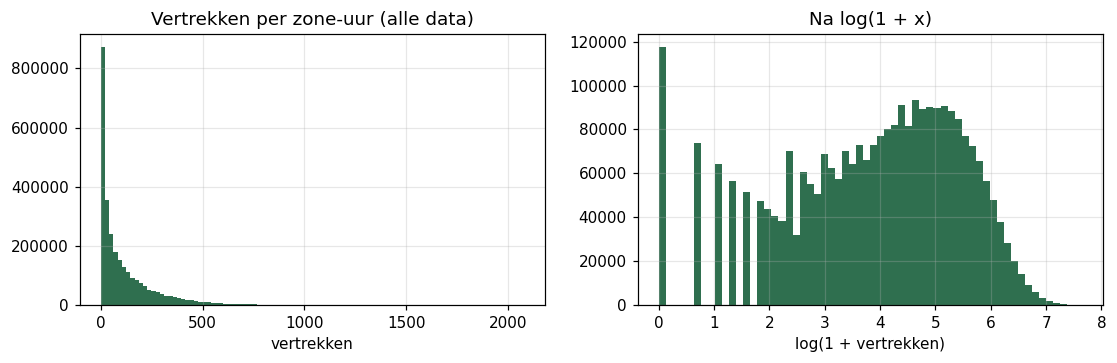

In [8]:
for name, t in [("2024", t24), ("alle data", table)]:
    print(f"{name:9}: gemiddeld {t['trips'].mean():.0f} vertrekken per zone-uur, variantie {t['trips'].var():,.0f}, "
          f"maximum {t['trips'].max():,}; {(t['trips'] == 0).mean():.1%} van de zone-uren zonder vertrek")
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
axes[0].hist(table["trips"], bins=100, color=GREEN); axes[0].set(title="Vertrekken per zone-uur (alle data)", xlabel="vertrekken")
axes[1].hist(np.log1p(table["trips"]), bins=60, color=GREEN); axes[1].set(title="Na log(1 + x)", xlabel="log(1 + vertrekken)")
plt.show()

**Vaststelling:**
- een **telling** (0, 1, 2, …), rechtsscheef, met een variantie die veel groter is dan het gemiddelde. Bij een zuivere Poisson-verdeling zijn die gelijk; hier is er sterke **overdispersie**, omdat de verwachting per zone en uur sterk verschilt;
- in 2024 heeft maar 0,3% van de zone-uren 0 vertrekken (vooral rustige zones 's nachts); over alle jaren 4% (de kleine netwerken van de eerste jaren). Ze expliciet als 0 opnemen (`01_cleaning` §13) is dus correct, en voor de eerste jaren ook belangrijk;
- uitschieters naar boven (drukke spitsuren) zijn **echte vraag**, geen meetfouten: die laten we staan.

**Gevolg:** we gebruiken modellen met een **Poisson-verliesfunctie** (voorspellingen altijd > 0, effecten vermenigvuldigend: "regen haalt er 30% af" in plaats van "regen haalt er 5 af") en meten naast de MAE ook de Poisson-deviance.

---
# Deel B – Testbare hypotheses (2024)
Vóór we modellen bouwen: is er een patroon dat **statistisch** standhoudt en **groot genoeg** is om te voorspellen? Twee hypotheses, vooraf vastgelegd.

**H1 – Regen.** In uren met neerslag vertrekken er minder fietsen dan in droge uren, **bij hetzelfde uur, daltype (weekdag/weekend) en maand**.
- H₀: neerslag verandert het aantal vertrekken niet (verhouding nat/droog = 1).
- H₁: in natte uren vertrekken er minder fietsen (verhouding < 1). Eenzijdig.

**H2 – Dagritme.** De verdeling van de vertrekken over de uren van de dag is op weekdagen anders dan in het weekend.
- H₀: de uurverdeling is gelijk op weekdagen en in het weekend.
- H₁: de uurverdeling verschilt.

**Significantieniveau:** α = 0,05.

**Waarom stratificeren?** Regen valt niet willekeurig: in NYC regent het bv. vaker 's nachts of in bepaalde maanden. Vergelijk je zomaar alle natte met alle droge uren, dan meet je deels "nacht vs. dag" of "winter vs. zomer" in plaats van regen (**confounding**). Door alleen uren te vergelijken die verder gelijk zijn (zelfde uur, daltype, maand), isoleren we het effect van regen.

**Waarom effectgroottes?** Met miljoenen ritten wordt elk verschil "significant". De vraag is of het verschil groot genoeg is om ertoe te doen. Daarom rapporteren we naast p-waarden altijd hoe groot het effect is, met een betrouwbaarheidsinterval.

We werken op het **stadstotaal per uur** (alle zones samen, 8.784 uren).

## B1. Regen verlaagt de vraag
**Definitie:** droog = 0 mm neerslag in dat uur; nat = ≥ 0,5 mm (echte regen, geen motregen). Uren daartussen laten we voor deze toets weg, zodat de twee groepen duidelijk verschillen (het model gebruikt wel de exacte hoeveelheid). Sneeuw telt als neerslag (Open-Meteo rekent smeltwater mee).

### Toets 1: gepaarde vergelijking per stratum (Wilcoxon signed-rank)
Per stratum (uur × daltype × maand) berekenen we het gemiddelde aantal vertrekken in natte en in droge uren; strata zonder natte of zonder droge uren vallen weg. Per stratum hebben we dan één **verhouding nat/droog**. Als regen niets uitmaakt, liggen die verhoudingen rond 1 (log-verhouding rond 0). De **Wilcoxon signed-rank-toets** rangschikt de log-verhoudingen en toetst of er systematisch meer negatieve zijn; hij veronderstelt geen normale verdeling.

{'droog': 7504, 'tussen': 715, 'nat': 565}
328 strata; in 95% minder vertrekken bij regen; mediaan nat/droog = 0.53; Wilcoxon W = 451, p = 4.8e-54


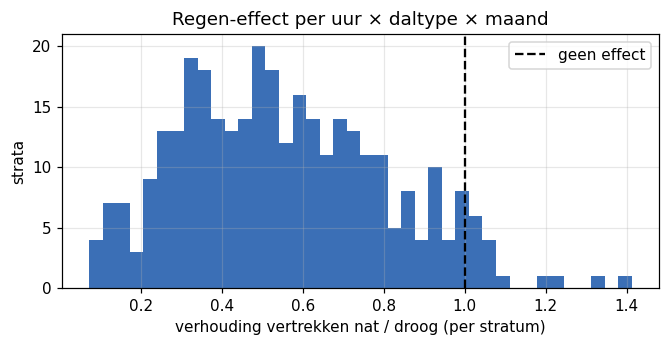

In [9]:
c = city24.copy()
c["month"] = c["time"].dt.month
c["wet"] = np.select([c["precipitation_mm"] == 0, c["precipitation_mm"] >= 0.5], ["droog", "nat"], "tussen")
print(c["wet"].value_counts().to_dict())
strata = c[c["wet"] != "tussen"].groupby(["hour", "daytype", "month", "wet"])["trips"].mean().unstack("wet").dropna()
strata = strata[(strata > 0).all(axis=1)]
log_ratio = np.log(strata["nat"] / strata["droog"])
wilcoxon = stats.wilcoxon(log_ratio, alternative="less")
print(f"{len(log_ratio)} strata; in {(log_ratio < 0).mean():.0%} minder vertrekken bij regen; "
      f"mediaan nat/droog = {np.exp(log_ratio.median()):.2f}; Wilcoxon W = {wilcoxon.statistic:.0f}, p = {wilcoxon.pvalue:.1e}")
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(np.exp(log_ratio), bins=40, color=BLUE)
ax.axvline(1, color="black", ls="--", label="geen effect")
ax.set(xlabel="verhouding vertrekken nat / droog (per stratum)", ylabel="strata", title="Regen-effect per uur × daltype × maand")
ax.legend()
plt.show()

### Toets 2: Poisson-regressie met vaste effecten (hoe groot is het effect?)
De Wilcoxon-toets zegt *of* er een effect is. Om te weten *hoe groot*, schatten we één model op alle natte en droge uren:

`log(verwacht aantal vertrekken) = effect(uur × daltype) + effect(dag) + β · nat`

- `effect(dag)`: één constante per **kalenderdag** (366 vaste effecten). Die vangt alles wat de hele dag geldt: seizoen, temperatuur van die dag, feestdagen. We vergelijken een nat uur dus met **droge uren van dezelfde dag**, op hetzelfde soort moment. `exp(β)` is de factor waarmee regen de vraag vermenigvuldigt.
- Technisch detail: het daltype zit al in het dag-effect (elke dag is een weekdag of een weekenddag). Daarom coderen we het uur apart binnen weekdagen en binnen weekenddagen, elk met 0u als referentie (`hour_weekday`, `hour_weekend`); anders is het model niet eenduidig bepaald.
- Tellingen zijn **overgedispergeerd**, en uren van dezelfde dag hangen samen. Gewone standaardfouten zouden dan te klein zijn (en de p-waarde te optimistisch). We gebruiken daarom **robuuste (sandwich) standaardfouten, geclusterd per dag**.

In [10]:
c["day"] = c["time"].dt.strftime("%m-%d")
c["hour_weekday"] = np.where(c["daytype"] == "weekdag", c["hour"], 0)
c["hour_weekend"] = np.where(c["daytype"] == "weekend", c["hour"], 0)
FIXED = "C(hour_weekday) + C(hour_weekend) + C(day)"
d = c[c["wet"] != "tussen"].assign(nat=lambda x: (x["wet"] == "nat").astype(int))
glm_h1 = smf.glm(f"trips ~ {FIXED} + nat", data=d, family=sm.families.Poisson()).fit(
    cov_type="cluster", cov_kwds={"groups": pd.factorize(d["day"])[0]})
lo, hi = glm_h1.conf_int().loc["nat"]
print(f"Binnen dezelfde dag: {np.exp(glm_h1.params['nat']) - 1:+.1%} vertrekken in een nat uur "
      f"(95%-BI {np.exp(lo) - 1:+.1%} tot {np.exp(hi) - 1:+.1%}), eenzijdige p = {stats.norm.cdf(glm_h1.tvalues['nat']):.1e}")

Binnen dezelfde dag: -26.9% vertrekken in een nat uur (95%-BI -32.3% tot -21.0%), eenzijdige p = 9.2e-16


**Resultaat H1:** H₀ wordt **verworpen**: regen verlaagt het aantal vertrekken duidelijk.
- **Per stratum** (328 combinaties): in **95%** van de strata vertrekken er minder fietsen bij regen, met als mediaan maar **53%** van de droge vraag (−47%). Wilcoxon: p ≈ 5·10⁻⁵⁴.
- **Binnen dezelfde dag**: een nat uur heeft **27% minder** vertrekken (95%-BI −32% tot −21%, p ≈ 10⁻¹⁵).

**Waarom zijn die twee getallen verschillend (−47% vs. −27%)?** Ze meten iets anders. De eerste vergelijkt natte uren met droge uren van *andere* dagen: daarin zit ook het effect van "het is een regendag" (wie 's ochtends regen ziet, laat de fiets de hele dag staan, ook in de droge uren). De tweede vergelijkt alleen binnen dezelfde dag en meet dus het effect van *dit uur* nat. Het model moet dus zowel het weer op het uur zelf als het weer van de dag kennen.

### Dosis-effect: hoe meer regen, hoe minder fietsers?
Een echt oorzakelijk verband toont vaak een **dosis-effect**. We herhalen het model met neerslagklassen in plaats van nat/droog, nu op alle uren.

In [11]:
data_all = c.assign(rain_class=pd.cut(c["precipitation_mm"], [-0.01, 0, 0.5, 2, 5, 100], labels=["droog", "0-0.5", "0.5-2", "2-5", ">5"]))
dose = smf.glm(f"trips ~ {FIXED} + C(rain_class)", data=data_all, family=sm.families.Poisson()).fit(
    cov_type="cluster", cov_kwds={"groups": pd.factorize(data_all["day"])[0]})
effects = dose.params.filter(like="rain_class")
ci = dose.conf_int().loc[effects.index]
labels = [name.split("[T.")[1][:-1] for name in effects.index]
pd.DataFrame({"effect t.o.v. droog (%)": (np.exp(effects.to_numpy()) - 1) * 100,
              "95%-BI laag (%)": (np.exp(ci[0].to_numpy()) - 1) * 100, "95%-BI hoog (%)": (np.exp(ci[1].to_numpy()) - 1) * 100,
              "aantal uren": data_all["rain_class"].value_counts()[labels].to_numpy()},
             index=[f"{label} mm/u" for label in labels]).round(1)

,effect t.o.v. droog (%),95%-BI laag (%),95%-BI hoog (%),aantal uren
0-0.5 mm/u,-11.1,-14.1,-8.0,773
0.5-2 mm/u,-25.1,-30.6,-19.2,336
2-5 mm/u,-34.2,-42.1,-25.3,129
>5 mm/u,-20.8,-31.0,-9.2,42


**Resultaat:** tot 5 mm per uur is er een duidelijk **dosis-effect**: motregen (≤ 0,5 mm) kost 11%, matige regen 25%, stevige regen 34%. Boven 5 mm per uur is het effect kleiner (−21%), maar dat zijn maar 42 uren in het hele jaar met een breed betrouwbaarheidsinterval. Zulke uren zijn vaak korte zomerse onweersbuien: mensen wachten ze af, of de bui viel niet op het punt waar het weermodel meet.

**Gevolg voor het model:** het effect is **niet lineair** in de hoeveelheid regen. Een boommodel kan dat zelf leren; in het lineaire model (C3) gebruiken we `log(1 + neerslag)`.

## B2. Het dagritme verschilt tussen weekdag en weekend
**Chi-kwadraattoets op homogeniteit:** een kruistabel met rijen = daltype, kolommen = uur, cellen = totaal aantal vertrekken. De toets vergelijkt de verdeling over de 24 uren. Met 44 miljoen ritten is de p-waarde praktisch 0, dus de **effectgrootte Cramér's V** (0 = geen verschil, 1 = volledig verschillend; vuistregel bij een 2 × k-tabel: 0,1 klein, 0,3 middelmatig, 0,5 groot) zegt hoe groot het verschil echt is.

chi² = 1,783,818 (df 23), p = 0.0e+00, n = 44,269,890 vertrekken, Cramér's V = 0.201


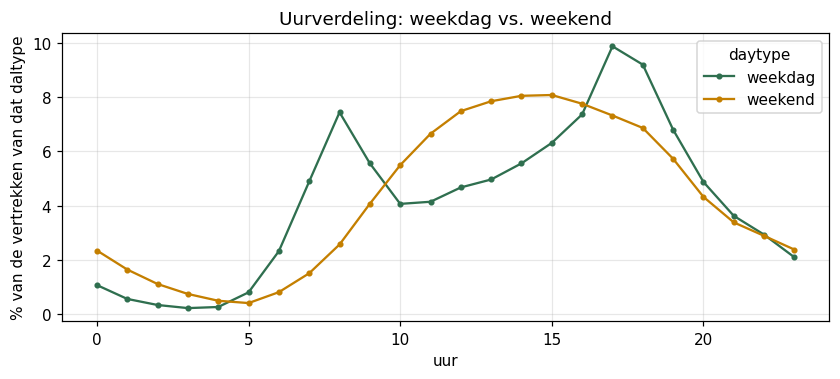

In [12]:
ct = city24.pivot_table(index="daytype", columns="hour", values="trips", aggfunc="sum")
chi2, p, dof, _ = stats.chi2_contingency(ct)
cramers_v = np.sqrt(chi2 / (ct.to_numpy().sum() * (min(ct.shape) - 1)))
print(f"chi² = {chi2:,.0f} (df {dof}), p = {p:.1e}, n = {ct.to_numpy().sum():,} vertrekken, Cramér's V = {cramers_v:.3f}")
shares = ct.div(ct.sum(axis=1), axis=0) * 100
fig, ax = plt.subplots(figsize=(9, 3.4))
shares.T.plot(ax=ax, color=[GREEN, ORANGE], marker="o", ms=3)
ax.set(xlabel="uur", ylabel="% van de vertrekken van dat daltype", title="Uurverdeling: weekdag vs. weekend")
plt.show()

**Strenger: de dag als eenheid.** De chi-kwadraattoets behandelt elke rit als onafhankelijk, maar ritten op dezelfde dag hangen samen (weer, evenementen). Per dag berekenen we daarom het aandeel van de vertrekken in de ochtendspits (7–9u), en vergelijken we weekdagen en weekenddagen met een **Mann–Whitney U-toets** (een niet-parametrische toets voor twee onafhankelijke groepen), met een bootstrap-interval voor het verschil in medianen.

In [13]:
per_day = (city24.assign(date=city24["time"].dt.normalize(), morning=city24["hour"].between(7, 9))
           .groupby(["date", "daytype"]).apply(lambda x: x.loc[x["morning"], "trips"].sum() / max(x["trips"].sum(), 1))
           .rename("ochtend").reset_index())
wd, we = (per_day.loc[per_day["daytype"] == k, "ochtend"] for k in ["weekdag", "weekend"])
mw = stats.mannwhitneyu(wd, we, alternative="two-sided")
rng = np.random.default_rng(SEED)
boot = [np.median(rng.choice(wd, len(wd))) - np.median(rng.choice(we, len(we))) for _ in range(2000)]
print(f"Mediaan aandeel 7-9u: weekdag {wd.median():.1%}, weekend {we.median():.1%}; verschil {wd.median() - we.median():+.1%} "
      f"(95%-BI {np.percentile(boot, 2.5):+.1%} .. {np.percentile(boot, 97.5):+.1%})")
print(f"Mann-Whitney U = {mw.statistic:.0f}, p = {mw.pvalue:.1e} ({len(wd)} weekdagen, {len(we)} weekenddagen)")

Mediaan aandeel 7-9u: weekdag 17.9%, weekend 8.3%; verschil +9.7% (95%-BI +9.2% .. +10.3%)
Mann-Whitney U = 26515, p = 2.8e-45 (262 weekdagen, 104 weekenddagen)


**Resultaat H2:** H₀ wordt **verworpen**: de uurverdeling verschilt.
- Cramér's V = 0,20: een klein tot middelmatig effect, wat veel is als je bedenkt dat 's nachts beide daltypes even stil zijn. De grafiek toont *hoe* ze verschillen: op weekdagen twee spitsen (8u: 7,5%, 17u: 10% van de vertrekken), in het weekend één brede bult met de top rond 15u.
- Met de **dag als eenheid**: het aandeel van de ochtendspits is op weekdagen **17,9%** en in het weekend **8,3%**. Het verschil van 9,7 procentpunt heeft een smal betrouwbaarheidsinterval (9,2 tot 10,3) en de Mann–Whitney-toets geeft p ≈ 3·10⁻⁴⁵.

(Feestdagen tellen hier als weekdag; het model krijgt ze apart via `is_holiday`.)

## B3. Hoeveel verklaren kalender en weer samen?
Een laatste controle vóór we modellen bouwen: verklaren deze factoren samen genoeg van de schommelingen om een voorspelmodel zinvol te maken? Twee eenvoudige Poisson-modellen op het stadstotaal: alleen *uur × daltype + maand*, en daarnaast ook het weer (temperatuur als spline, `log(1 + neerslag)`, wind). Maat: het aandeel van de **deviance** dat het model verklaart (zoals R², maar voor tellingen).

In [14]:
city_m = city24.assign(month=city24["time"].dt.month, slot=city24["hour"].astype(str) + "_" + city24["daytype"],
                       log_precip=np.log1p(city24["precipitation_mm"]))
base_glm = smf.glm("trips ~ C(slot) + C(month)", data=city_m, family=sm.families.Poisson()).fit()
full_glm = smf.glm("trips ~ C(slot) + C(month) + bs(temperature_c, df=4) + log_precip + wind_kmh",
                   data=city_m, family=sm.families.Poisson()).fit()
explained = {"uur x daltype + maand": 1 - base_glm.deviance / base_glm.null_deviance,
             "+ weer": 1 - full_glm.deviance / base_glm.null_deviance}
print({k: f"{v:.1%} van de deviance verklaard" for k, v in explained.items()})

{'uur x daltype + maand': '89.1% van de deviance verklaard', '+ weer': '92.5% van de deviance verklaard'}


**Resultaat:** op het niveau van de hele stad verklaart de kalender alleen al **89%** van de deviance. Het weer voegt daar nog **3,4 procentpunt** aan toe (92,5%). De kalender bepaalt het grootste deel van het patroon, maar het weer maakt het verschil tussen een gewone en een "slechte" dag, precies de dagen waarop een planner het model nodig heeft. Per zone zal het moeilijker zijn: daar is er meer toeval, en elke zone heeft een eigen dagpatroon (A4).

### Conclusie deel B
| Hypothese | Toets | Resultaat | Effectgrootte |
|---|---|---|---|
| H1: minder vertrekken bij regen | Wilcoxon per stratum; Poisson met dag-effecten | H₀ verworpen (p < 10⁻¹⁵) | −27% per nat uur (BI −32% tot −21%); dosis-effect tot 5 mm/u |
| H2: ander dagritme in het weekend | chi² + Mann–Whitney per dag | H₀ verworpen (p < 10⁻⁴⁴) | Cramér's V = 0,20; ochtendspits 17,9% vs. 8,3% |

Er is dus een **sterk, statistisch onderbouwd en praktisch relevant patroon** om te voorspellen, en de kenmerken liggen vast: zone, uur, weekdag/weekend, maand, feestdag, temperatuur, neerslag (niet-lineair) en wind.

---
# Deel C – Modelselectie op 2024
## C0. Opzet
- **Data:** 30 zones × alle uren van 2024 = 263.520 zone-uren.
- **Kenmerken** (`make_features`): zone, uur, weekdag, maand, weekend, feestdag (officiële Amerikaanse feestdagen), temperatuur, neerslag, wind. Alles is gekend op het moment dat je een voorspelling vraagt (geen *leakage*). Dezelfde functie staat in de API (`deploy/citi_bike_demand/api.py`).
- **Testset:** de laatste 7 dagen van elke maand (`01_cleaning` §17). Zo zit elk seizoen in de test en zijn de test-uren blokken van een week. De testset gebruiken we per model maar **één keer**, op het einde.
- **Validatie bij het kiezen en tunen:** 5-voudige `GroupKFold` met de **kalenderweek** als groep: uren uit dezelfde week zitten nooit tegelijk in train en validatie. Naburige uren lijken sterk op elkaar (**autocorrelatie**); als 8u in de training zit en 9u in de validatie, ziet het model bijna het antwoord (**data leakage**) en is de score te mooi.
- **Metrics:**
  - **MAE** (primair): "gemiddeld zitten we x vertrekken per uur naast". Makkelijk uit te leggen aan een planner;
  - **RMSE**: straft grote fouten zwaarder (bv. een gemiste spits);
  - **R²**: welk deel van de variatie verklaren we?
  - **Poisson-deviance**: de "natuurlijke" foutmaat voor tellingen: een fout van 5 bij een verwachting van 2 is erger dan een fout van 5 bij een verwachting van 200.

**Waarom deze modellen?** Een **baseline** om te weten wat "goed" is; een **Poisson-GLM** omdat het uitlegbaar is; twee boom-ensembles uit de twee families (**bagging**: random forest; **boosting**: gradient boosting) omdat ze interacties zelf vinden; **PyCaret** (AutoML) als onafhankelijke controle; en een experiment met **lags**.

In [15]:
FEATURES_2024 = ["zone", "hour", "weekday", "month", "is_weekend", "is_holiday", "temperature_c", "precipitation_mm", "wind_kmh"]
FEATURES = FEATURES_2024 + ["year", "active_stations", "snow_depth_cm"]      # alle data, zie deel D


def us_holidays(start, end) -> pd.DatetimeIndex:
    return USFederalHolidayCalendar().holidays(start=start, end=end)


def make_features(frame: pd.DataFrame, features: list[str] = FEATURES) -> pd.DataFrame:
    """Kenmerken uit (zone, time, weer[, active_stations, snow_depth_cm]). Dezelfde logica staat in de API."""
    time_ = pd.to_datetime(frame["time"])
    out = pd.DataFrame(index=frame.index)
    out["zone"] = frame["zone"].astype(int)
    out["hour"] = time_.dt.hour
    out["weekday"] = time_.dt.dayofweek
    out["month"] = time_.dt.month
    out["is_weekend"] = (out["weekday"] >= 5).astype(int)
    out["is_holiday"] = time_.dt.normalize().isin(us_holidays(time_.min().normalize(), time_.max().normalize())).astype(int)
    out["temperature_c"] = frame["temperature_c"].astype(float)
    out["precipitation_mm"] = frame["precipitation_mm"].astype(float)
    out["wind_kmh"] = frame["wind_kmh"].astype(float)
    out["year"] = time_.dt.year
    if "active_stations" in frame:
        out["active_stations"] = frame["active_stations"].astype(int)
    if "snow_depth_cm" in frame:
        out["snow_depth_cm"] = frame["snow_depth_cm"].astype(float)
    return out[features]


def cv_groups(time_: pd.Series) -> pd.Series:
    """Groep voor GroupKFold: de kalenderweek."""
    iso = pd.to_datetime(time_).dt.isocalendar()
    return (iso["year"].astype(int) * 100 + iso["week"].astype(int)).rename("week")


def train_test(tab: pd.DataFrame, features: list[str] = FEATURES):
    """(X_train, y_train, groups_train, X_test, y_test) volgens de split-kolom van de tabel."""
    X, y = make_features(tab, features), tab["trips"]
    is_test = (tab["split"] == "test").to_numpy()
    groups = cv_groups(tab["time"])
    return X[~is_test], y[~is_test], groups[~is_test], X[is_test], y[is_test]


def evaluate(y_true, y_pred) -> dict:
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.clip(np.asarray(y_pred, dtype=float), 1e-6, None)    # Poisson-deviance vraagt > 0
    return {"mae": round(float(mean_absolute_error(y_true, y_pred)), 4),
            "rmse": round(float(np.sqrt(mean_squared_error(y_true, y_pred))), 4),
            "r2": round(float(r2_score(y_true, y_pred)), 4),
            "poisson_deviance": round(float(mean_poisson_deviance(y_true, y_pred)), 4)}


def _poisson_deviance_clipped(y_true, y_pred):
    return mean_poisson_deviance(y_true, np.clip(y_pred, 1e-6, None))   # een voorspelling van exact 0 mag niet (log 0)


POISSON_SCORER = make_scorer(_poisson_deviance_clipped, greater_is_better=False)


def cv_scores(model, X, y, groups=None, n_splits: int = 5, cv=None) -> dict:
    """MAE en Poisson-deviance per fold: standaard GroupKFold op kalenderweken, of de opgegeven folds."""
    result = cross_validate(model, X, y, groups=groups, cv=cv if cv is not None else GroupKFold(n_splits=n_splits),
                            scoring={"mae": "neg_mean_absolute_error", "dev": POISSON_SCORER}, n_jobs=1)
    mae = (-result["test_mae"]).round(4).tolist()
    return {"cv_mae": mae, "cv_mae_mean": round(float(np.mean(mae)), 4),
            "cv_poisson_deviance": (-result["test_dev"]).round(4).tolist(), "cv_fit_seconds": round(float(np.sum(result["fit_time"])), 1)}


def hgb(features=FEATURES, **params) -> HistGradientBoostingRegressor:
    """HistGradientBoosting met Poisson-verlies en de zone als categorie (de uiteindelijk gekozen techniek)."""
    return HistGradientBoostingRegressor(loss="poisson", categorical_features=[features.index("zone")], random_state=SEED, **params)


def cached(name: str, run) -> pd.DataFrame:
    """Resultaat van een zoektocht: bewaard in models/searches/<name>.csv, of (opnieuw) berekend."""
    path = SEARCH_DIR / f"{name}.csv"
    if RUN_SEARCHES or not path.exists():
        SEARCH_DIR.mkdir(parents=True, exist_ok=True)
        run().to_csv(path, index=False)
    return pd.read_csv(path)


def search_table(search) -> pd.DataFrame:
    """Alle geprobeerde combinaties van een zoektocht, beste eerst."""
    return (pd.DataFrame(search.cv_results_["params"])
              .assign(cv_mae=-search.cv_results_["mean_test_score"], std_over_folds=search.cv_results_["std_test_score"],
                      fit_seconds=search.cv_results_["mean_fit_time"])
              .sort_values("cv_mae").reset_index(drop=True))


def best_params(results: pd.DataFrame, ints=(), digits=None) -> dict:
    """Beste rij van een zoektabel als parameters (NaN = None, gehele getallen als int)."""
    row = results.drop(columns=["cv_mae", "std_over_folds", "fit_seconds"]).iloc[0]
    out = {}
    for k, v in row.items():
        if pd.isna(v):
            out[k] = None
        elif k in ints:
            out[k] = int(v)
        else:
            out[k] = round(float(v), digits) if digits else float(v)
    return out


def per_fold(scores: dict) -> pd.DataFrame:
    return pd.DataFrame({name: {"cv_mae": s["cv_mae_mean"], **{f"fold {i}": m for i, m in enumerate(s["cv_mae"])}}
                         for name, s in scores.items()}).T


X24, y24, g24, X24t, y24t = train_test(t24, FEATURES_2024)
F24 = FEATURES_2024
results24, preds24, cv24 = {}, {}, {}


def test_frame(tab, y_test, pred):
    return tab.loc[y_test.index, ["zone", "time", "trips"]].assign(pred=pred)


def record(name, cv, pred, extra=None):
    """Bewaar CV en testmeting van een model van de 2024-studie."""
    cv24[name] = cv
    results24[name] = {"cv_mae": cv["cv_mae_mean"] if cv else None, **evaluate(y24t, pred),
                       "fit_s (5 folds)": cv["cv_fit_seconds"] if cv else None, **(extra or {})}
    preds24[name] = test_frame(t24, y24t, pred)
    return pd.Series(results24[name])


print(f"train: {len(X24):,} zone-uren in {g24.nunique()} weken | test: {len(X24t):,} zone-uren")
X24.head()

train: 203,040 zone-uren in 50 weken | test: 60,480 zone-uren


,zone,hour,weekday,month,is_weekend,is_holiday,temperature_c,precipitation_mm,wind_kmh
0,0,0,0,1,0,1,1.8,0.1,7.4
1,0,1,0,1,0,1,1.3,0.0,8.7
2,0,2,0,1,0,1,2.4,0.0,10.4
3,0,3,0,1,0,1,2.7,0.0,9.2
4,0,4,0,1,0,1,2.7,0.0,7.9


## C1. Baselines
Een model is pas nuttig als het beter doet dan wat een planner met Excel zou doen. We proberen drie steeds fijnere gemiddelden uit de trainset (`GroupMeanRegressor`):

| Baseline | Voorspelling |
|---|---|
| globaal | het gemiddelde over alle zones en uren |
| per zone | het gemiddelde van die zone |
| **per zone × uur × weekdag/weekend** | "hoeveel vertrekken er gemiddeld in deze zone om 8u op een weekdag?" |

De laatste is de echte lat: hij kent het dagpatroon van elke zone al, alleen het weer en het seizoen niet.

In [16]:
class GroupMeanRegressor:
    """Baseline: het gemiddelde van de trainset voor dezelfde combinatie van `keys` (onbekend: globaal gemiddelde).
    Met `recent_months` tellen alleen de laatste maanden van de trainset mee (kolommen `year` en `month` nodig)."""

    def __init__(self, keys=("zone", "hour", "is_weekend"), recent_months=None):
        self.keys = keys
        self.recent_months = recent_months

    def get_params(self, deep=True):
        return {"keys": self.keys, "recent_months": self.recent_months}

    def set_params(self, **params):
        for key, value in params.items():
            setattr(self, key, value)
        return self

    def fit(self, X, y):
        keys = list(self.keys)
        y = pd.Series(np.asarray(y), index=X.index)
        if self.recent_months:
            period = X["year"] * 12 + X["month"]
            recent = period > period.max() - self.recent_months
            X, y = X[recent], y[recent]
        self.global_mean_ = float(np.mean(y))
        self.means_ = pd.DataFrame(X[keys]).assign(_y=y.to_numpy()).groupby(keys)["_y"].mean() if keys else None
        return self

    def predict(self, X):
        if not self.keys:
            return np.full(len(X), self.global_mean_)
        index = pd.MultiIndex.from_frame(X[list(self.keys)]) if len(self.keys) > 1 else X[self.keys[0]]
        return self.means_.reindex(index).fillna(self.global_mean_).to_numpy()


base_scores = {name: cv_scores(GroupMeanRegressor(keys=keys), X24, y24, g24)
               for name, keys in [("globaal gemiddelde", ()), ("gemiddelde per zone", ("zone",)),
                                  ("gemiddelde per zone x uur x weekend", ("zone", "hour", "is_weekend"))]}
display(per_fold(base_scores).round(1))
base = GroupMeanRegressor(keys=("zone", "hour", "is_weekend"))
record("baseline", base_scores["gemiddelde per zone x uur x weekend"], base.fit(X24, y24).predict(X24t))

,cv_mae,fold 0,fold 1,fold 2,fold 3,fold 4
globaal gemiddelde,138.4,140.0,136.2,142.4,132.4,141.1
gemiddelde per zone,116.9,119.1,113.9,123.1,108.4,120.2
gemiddelde per zone x uur x weekend,59.2,60.6,58.5,70.0,52.4,54.5


cv_mae              59.1855
mae                 59.2751
rmse                96.4412
r2                   0.7235
poisson_deviance    34.1876
fit_s (5 folds)      0.2000
dtype: float64

**Resultaat:**
- het **globale gemiddelde** zit gemiddeld 138 vertrekken per uur naast: het weet niets;
- **per zone** helpt weinig (117): het verschil tussen zones is kleiner dan het verschil tussen dag en nacht;
- **zone × uur × weekend** halveert de fout (59; test 59,3, R² 0,72). Het dagritme per plaats is dus de grootste bron van informatie, precies wat de EDA (A3, A4) en H2 voorspelden;
- de fout verschilt per fold (52 tot 70): sommige weken zijn moeilijker (zomer met meer ritten, weken met veel regen). Daarom vergelijken we modellen altijd **op dezelfde folds**.

**Verder?** Ja, als **lat**: elk model moet duidelijk onder MAE 59 zitten.

## C2. Een snel eerste model: gradient boosting met standaardinstellingen
Om de deployment (API en webpagina) al te kunnen bouwen terwijl we verder tunen, namen we meteen een "echt" model: `HistGradientBoostingRegressor` van scikit-learn, **zonder te tunen**:
- **boosting**: bomen **na elkaar**, elke nieuwe kleine boom leert de fouten van alle vorige samen; op tabeldata meestal het sterkst. Vindt zelf de interacties (zone × uur × weekend × regen) die een lineair model met de hand moet krijgen;
- de **histogram**-variant deelt elke numerieke kolom eerst in maximaal 255 bakjes in: snel op honderdduizenden rijen (vergelijkbaar met LightGBM);
- **`loss="poisson"`**: voorspelt tellingen (nooit negatief, fout relatief tot de verwachting);
- **zone als categorische variabele** (`categorical_features`): zone 7 is niet "groter" dan zone 3, en een split kan elke groep zones afzonderen;
- scikit-learn staat al op de server: geen extra bibliotheek voor de API.

In [17]:
quick = hgb(F24)
record("quick_hgb", cv_scores(quick, X24, y24, g24), quick.fit(X24, y24).predict(X24t))
display(per_fold({"baseline": cv24["baseline"], "snel model": cv24["quick_hgb"]}).round(2))
pd.DataFrame(results24).T[["cv_mae", "mae", "rmse", "r2", "poisson_deviance"]]

,cv_mae,fold 0,fold 1,fold 2,fold 3,fold 4
baseline,59.19,60.57,58.49,69.99,52.40,54.48
snel model,27.57,27.83,28.36,25.59,28.04,28.00


,cv_mae,mae,rmse,r2,poisson_deviance
baseline,59.1855,59.2751,96.4412,0.7235,34.1876
quick_hgb,27.5663,30.8826,57.1495,0.9029,13.3123


**Resultaat:** het ongetunede boosting-model **halveert de fout opnieuw**: MAE 31 tegenover 59 voor de beste baseline, en R² 0,90 tegenover 0,72, in elke fold. Wat het extra weet ten opzichte van de baseline: het weer, de maand (seizoen), de weekdag (vrijdag ≠ dinsdag) en feestdagen.

De testfout (30,9) is iets hoger dan de CV-fout (27,6). De testweken bevatten enkele moeilijke dagen: Thanksgiving (28/11), Kerstmis en oudejaar, en Memorial Day (27/5) vallen allemaal in de laatste week van hun maand. In C9 kijken we of de grootste fouten daar zitten.

**Verder?** Ja: dit was de eerste versie in de API, zodat de webpagina gebouwd en getest kon worden. In C6 tunen we het.

## C3. Poisson-GLM: het uitlegbare model
**Waarom:** een Poisson-GLM (*generalized linear model*) voorspelt `log(vraag) = som van effecten`; na `exp` zijn de effecten **factoren** ("regen haalt er 30% af") die je aan een planner kan uitleggen. 30% minder is in een drukke zone veel meer ritten dan in een rustige: dat past bij tellingen.

Een lineair model vindt geen interacties zelf. Uit A4 weten we dat elke zone een **eigen dagpatroon** heeft; dat moeten we hem expliciet geven. Kenmerken:
- `slot` = uur + 24 × weekend: 48 "momenten";
- `zone_slot` = combinatie zone × slot (alleen in de variant met interactie): 30 × 48 = 1.440 kolommen;
- categorieën via **one-hot encoding** (één 0/1-kolom per waarde, want categorieën zijn geen getallen);
- **temperatuur** via een **spline** (een gebogen curve uit stukjes polynoom): te koud én te warm is minder fietsweer;
- **neerslag** via `log1p`: het verschil tussen 0 en 1 mm is groot (droog vs. nat), dat tussen 10 en 11 mm niet (zie het dosis-effect in B1);
- wind: geschaald.

We vergelijken een **additief** model (zone + slot + ...) met het model **met interactie**, eerst met een kleine **L2-regularisatie** (`alpha = 1e-4`, een straf op grote coëfficiënten).

In [18]:
def add_keys(X):
    X = X.copy()
    X["slot"] = X["hour"] + 24 * X["is_weekend"]
    X["zone_slot"] = X["zone"] * 48 + X["slot"]
    X["log_precip"] = np.log1p(X["precipitation_mm"])
    return X


def glm(interaction: bool, alpha: float = 1e-4):
    pre = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), (["zone_slot"] if interaction else ["zone", "slot"]) + ["month", "is_holiday"]),
        ("temp", SplineTransformer(n_knots=6, degree=3), ["temperature_c"]),
        ("num", StandardScaler(), ["log_precip", "wind_kmh"])])
    return make_pipeline(FunctionTransformer(add_keys), pre, PoissonRegressor(alpha=alpha, solver="newton-cholesky", max_iter=300))


glm_variants = {name: cv_scores(glm(interaction), X24, y24, g24) for name, interaction in [("additief", False), ("zone x uur x weekend", True)]}
per_fold(glm_variants).round(2)

,cv_mae,fold 0,fold 1,fold 2,fold 3,fold 4
additief,37.34,37.17,38.25,35.34,36.86,39.10
zone x uur x weekend,30.46,29.57,31.82,27.67,31.27,31.96


**Resultaat:** de interactie **zone × uur × weekend** verlaagt de MAE van 37,3 naar 30,5, en dat in elke fold. Dit bevestigt de stationsprofielen (A4): een additief model moet voor alle zones hetzelfde uurpatroon gebruiken en zit daardoor systematisch naast. De prijs: 1.440 extra kolommen, maar het model blijft snel.

### Regularisatie tunen (grid search)
Met 1.440 zone×slot-kolommen kan het model ruis in zeldzame combinaties (rustige zone, 4u 's nachts) gaan volgen; een grotere `alpha` trekt die coëfficiënten naar 0. We zoeken de beste waarde met **GridSearchCV**: elke waarde van een rooster (log-schaal), telkens met dezelfde 5 week-folds.

In [19]:
def run_glm_grid():
    search = GridSearchCV(glm(True), {"poissonregressor__alpha": [1e-6, 1e-5, 1e-4, 1e-3, 1e-2]},
                          cv=GroupKFold(5), scoring="neg_mean_absolute_error", n_jobs=1).fit(X24, y24, groups=g24)
    return search_table(search).rename(columns={"poissonregressor__alpha": "alpha"})


glm_grid = cached("glm_alpha_2024", run_glm_grid)
glm_alpha = float(glm_grid.loc[0, "alpha"])
glm_grid.sort_values("alpha").round(4)

,alpha,cv_mae,std_over_folds,fit_seconds
0,0.0000,30.4538,1.6374,10.4922
1,0.0000,30.4541,1.6369,10.5107
2,0.0001,30.4597,1.6332,11.3406
3,0.0010,30.6382,1.6228,9.0180
4,0.0100,34.5477,1.9872,9.4492


**Resultaat:** regularisatie maakt hier weinig uit. Van `alpha = 1e-6` tot `1e-4` is de MAE gelijk (30,45); pas bij `1e-2` wordt het slechter (34,5), omdat de straf dan echte verschillen tussen zones en uren wegdrukt. Met 200.000 rijen en "maar" 1.500 coëfficiënten (± 135 uren per coëfficiënt) is er weinig risico op overfitting. We nemen de beste waarde (`1e-6`).

### Wat leert het model? Coëfficiënten als vermenigvuldigingsfactoren
Dit is de echte meerwaarde van een GLM: `exp(coëfficiënt)` = factor waarmee de vraag vermenigvuldigd wordt. We bekijken het weer en de kalender (de 1.440 zone×slot-coëfficiënten tonen we niet allemaal).

Neerslag 1 mm/u t.o.v. droog: x 0.70 (-30%)
Neerslag 5 mm/u t.o.v. droog: x 0.40 (-60%)
Feestdag t.o.v. gewone dag: x 0.83
Maand t.o.v. januari: {1: 1.0, 2: 1.15, 3: 1.21, 4: 1.29, 5: 1.36, 6: 1.47, 7: 1.32, 8: 1.38, 9: 1.59, 10: 1.7, 11: 1.61, 12: 1.32}


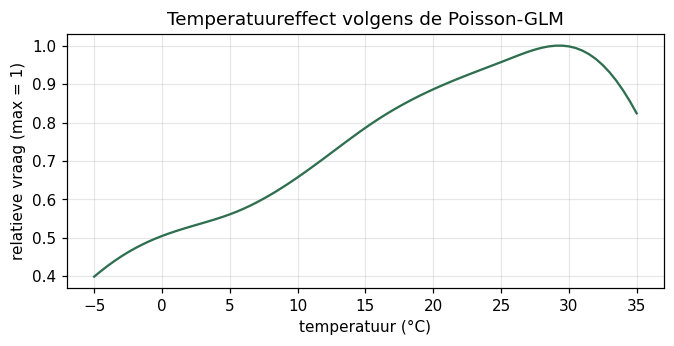

Optimum: 29.5 °C


cv_mae              30.453800
mae                 33.189200
rmse                60.397100
r2                   0.891600
poisson_deviance    14.589400
fit_s (5 folds)     20.700000
alpha                0.000001
dtype: float64

In [20]:
glm_model = glm(True, glm_alpha)
record("poisson_glm", cv_scores(glm_model, X24, y24, g24), glm_model.fit(X24, y24).predict(X24t), {"alpha": glm_alpha})
pre, reg = glm_model[1], glm_model[-1]
coefs = pd.Series(reg.coef_, index=pre.get_feature_names_out())
sd = pre.named_transformers_["num"].scale_[0]                       # standaardafwijking van log1p(neerslag)
for mm in [1, 5]:
    factor = np.exp(coefs["num__log_precip"] * np.log1p(mm) / sd)
    print(f"Neerslag {mm} mm/u t.o.v. droog: x {factor:.2f} ({factor - 1:+.0%})")
print(f"Feestdag t.o.v. gewone dag: x {np.exp(coefs['cat__is_holiday_1'] - coefs['cat__is_holiday_0']):.2f}")
months = coefs.filter(like="cat__month_")
print("Maand t.o.v. januari:", dict(zip(range(1, 13), np.exp(months - months.iloc[0]).round(2).tolist())))
temps = np.linspace(-5, 35, 81)
probe = X24.iloc[[0] * len(temps)].assign(temperature_c=temps, precipitation_mm=0.0, wind_kmh=10.0)
curve = glm_model.predict(probe)
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(temps, curve / curve.max(), color=GREEN)
ax.set(xlabel="temperatuur (°C)", ylabel="relatieve vraag (max = 1)", title="Temperatuureffect volgens de Poisson-GLM")
plt.show()
print(f"Optimum: {temps[np.argmax(curve)]:.1f} °C")
pd.Series(results24["poisson_glm"])

**Resultaat:** op de testset **MAE 33,2, R² 0,89**. Wat het model ons "gratis" leert:
- regen: **−30%** bij 1 mm/u, −60% bij 5 mm/u (in lijn met H1: −27% voor een nat uur);
- feestdag: **−17%** ten opzichte van een gewone dag op hetzelfde moment;
- **maand** (bovenop het temperatuureffect!): oktober heeft 1,7 keer de vraag van januari **bij dezelfde temperatuur**; september tot november zijn de sterkste maanden (forenzen en studenten zijn terug). Dit verklaart waarom de piek in A2 niet in juli ligt;
- **temperatuur**: de vraag stijgt bijna lineair van −5 °C (± 40% van het maximum) tot een optimum rond **29 °C**, en daalt daarboven.

**Verder?** **Nee, niet als voorspeller.** Het blijft duidelijk minder goed dan de bomen hieronder: het mist interacties die we niet zelf bouwden (bv. regen × weekend, uit A3), en de `log1p`-vorm dwingt een steeds groter regeneffect af, terwijl B1 een afvlakking boven 5 mm/u toont. We gebruiken het wel voor de **uitleg** van de effecten.

## C4. Random forest
**Waarom:**
- een random forest middelt **veel diepe beslissingsbomen**, elk getraind op een andere **bootstrap-steekproef** van de rijen en met willekeurige subsets van kenmerken per split. Het middelen (**bagging**) verlaagt de variantie van één diepe boom (die zou overfitten);
- bomen vinden **interacties zelf**, in tegenstelling tot de GLM;
- het is het "andere" ensemble-type naast boosting: **bagging** (parallel, onafhankelijke bomen) tegenover **boosting** (na elkaar, elke boom corrigeert de vorige). Zo vergelijken we de twee families.

**Zone als getal:** de random forest van scikit-learn kent geen categorische kenmerken; zone staat er als getal 0–29. De zones zijn genummerd van druk naar rustig, dus een split "zone ≤ 5" betekent "de drukste zones" en is zinvol.

**Verliesfunctie:** de standaard `squared_error`. Het `poisson`-criterium bestaat ook, maar is op 200.000 rijen veel trager; een boom voorspelt toch gemiddelden van tellingen (nooit negatief).

Eerst met **standaardinstellingen** (100 bomen, onbeperkte diepte, alle kenmerken per split, bladeren van 1 uur):

In [21]:
rf_default = cv_scores(RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=SEED), X24, y24, g24)
per_fold({"standaard (100 bomen)": rf_default}).round(2)

,cv_mae,fold 0,fold 1,fold 2,fold 3,fold 4
standaard (100 bomen),28.14,27.97,30.87,24.66,30.18,27.03


### Randomized search, ronde 1: breed zoeken
**RandomizedSearchCV** probeert willekeurige combinaties uit een zoekruimte (efficiënter dan alle combinaties proberen). Wat we tunen:

| Hyperparameter | Effect |
|---|---|
| `min_samples_leaf` | minimum aantal uren per blad: groter = gladder, minder ruis volgen |
| `max_features` | aandeel kenmerken per split: kleiner = meer verschillende bomen (minder correlatie) |
| `max_depth` | maximale diepte: begrenst de complexiteit |
| `max_samples` | grootte van de bootstrap-steekproef per boom: kleiner = sneller en diverser |

12 combinaties × 3 week-folds, met 150 bomen. We verwachtten dat grotere bladeren en minder kenmerken per split overfitting zouden tegengaan.

In [22]:
def run_rf_round1():
    search = RandomizedSearchCV(RandomForestRegressor(n_estimators=150, n_jobs=-1, random_state=SEED),
                                {"min_samples_leaf": randint(1, 30), "max_features": uniform(0.3, 0.7),
                                 "max_depth": [None, 12, 18, 25], "max_samples": uniform(0.3, 0.7)},
                                n_iter=12, cv=GroupKFold(3), scoring="neg_mean_absolute_error", random_state=SEED, n_jobs=1)
    return search_table(search.fit(X24, y24, groups=g24))


rf_round1 = cached("rf_round1_2024", run_rf_round1)
display(rf_round1.head(6).round(3))
print("Slechtste combinaties:")
rf_round1.tail(3).round(3)

,max_depth,max_features,max_samples,min_samples_leaf,cv_mae,std_over_folds,fit_seconds
0,18.0,0.902,0.776,9,30.919,2.155,15.076
1,18.0,0.858,0.428,8,31.565,2.027,6.911
2,18.0,0.621,0.534,8,32.390,2.021,7.932
3,NaN,0.718,0.612,23,34.284,2.029,7.215
4,NaN,0.732,0.728,29,34.783,2.042,5.142
5,25.0,0.505,0.556,15,35.272,1.975,3.028


Slechtste combinaties:


,max_depth,max_features,max_samples,min_samples_leaf,cv_mae,std_over_folds,fit_seconds
9,25.0,0.316,0.667,10,41.843,2.283,2.358
10,18.0,0.309,0.960,14,42.074,2.198,2.753
11,12.0,0.440,0.660,25,42.833,2.274,3.882


**Resultaat ronde 1:** de tuning maakte het model **slechter**. De beste combinatie haalt CV-MAE 30,9, terwijl de standaardinstellingen 28,1 haalden (met 5 folds in plaats van 3, maar het verschil is groter dan de spreiding over de folds, ± 2). Het patroon in de tabel is duidelijk:
- de beste combinaties gebruiken **bijna alle kenmerken per split** (`max_features` 0,86–0,90) en **kleine bladeren** (8–9 uren);
- de slechtste gebruiken maar 30% van de kenmerken per split (MAE 42).

Dat verklaart het: de standaard random forest voor regressie gebruikt **alle** kenmerken en bladeren van **1** uur. Onze zoekruimte sloot precies dat gebied uit. Met maar 9 kenmerken, waarvan 3 (uur, zone, temperatuur) het meeste werk doen, is een split zonder `hour` of `zone` vaak een slechte split. En grote bladeren middelen het zone × uur-detail weg.

### Ronde 2: zoeken rond de standaardinstellingen
Nu in de buurt van wat werkt: kleine bladeren (1–7), veel kenmerken per split (60–100%), weinig of geen dieptebeperking; 15 combinaties met dezelfde 5 folds als alle andere modellen.

In [23]:
def run_rf_round2():
    search = RandomizedSearchCV(RandomForestRegressor(n_estimators=150, n_jobs=-1, random_state=SEED),
                                {"min_samples_leaf": randint(1, 8), "max_features": uniform(0.6, 0.4),
                                 "max_depth": [None, 25, 35], "max_samples": uniform(0.5, 0.5)},
                                n_iter=15, cv=GroupKFold(5), scoring="neg_mean_absolute_error", random_state=SEED, n_jobs=1)
    return search_table(search.fit(X24, y24, groups=g24))


rf_round2 = cached("rf_round2_2024", run_rf_round2)
rf_round2.head(6).round(3)

,max_depth,max_features,max_samples,min_samples_leaf,cv_mae,std_over_folds,fit_seconds
0,25.0,0.810,0.716,1,27.477,2.172,15.390
1,35.0,0.872,0.725,2,27.617,2.202,10.640
2,NaN,0.986,0.904,1,27.688,2.161,16.694
3,35.0,0.782,0.893,3,27.761,2.136,10.711
4,35.0,0.844,0.917,3,27.762,2.180,10.865
5,25.0,0.600,0.996,1,27.771,2.079,14.027


**Resultaat ronde 2:** nu liggen alle beste combinaties rond CV-MAE 27,5 tot 27,8, beter dan de standaard. De winnaars hebben **bladeren van 1 tot 3 uren**, **60–100% van de kenmerken** per split en een **bootstrap-steekproef van ± 70–90%** van de rijen. Dat laatste is de enige echte verbetering ten opzichte van de standaard: iets kleinere steekproeven per boom maken de bomen onderling diverser, en het gemiddelde van diversere bomen is beter. De verschillen binnen de top 6 (0,3) zijn wel klein ten opzichte van de spreiding over de folds (± 2,2).

### Standaard of getuned?
We vergelijken de standaardinstellingen en de beste combinatie uit ronde 2 op exact dezelfde 5 folds, elk met 300 bomen, en houden het model met de laagste CV-MAE. (Zoals PyCaret's `choose_better=True`: tunen mag het model nooit slechter maken.)

In [24]:
rf_candidates = {"standaard": {}, "getuned (ronde 2)": best_params(rf_round2, ints=("min_samples_leaf", "max_depth"))}
rf_scores = {name: cv_scores(RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=SEED, **params), X24, y24, g24)
             for name, params in rf_candidates.items()}
display(per_fold(rf_scores).round(3))
rf_chosen = min(rf_scores, key=lambda name: rf_scores[name]["cv_mae_mean"])
rf = RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=SEED, **rf_candidates[rf_chosen]).fit(X24, y24)
print("Gekozen:", rf_chosen, rf_candidates[rf_chosen])
record("random_forest", rf_scores[rf_chosen], rf.predict(X24t))

,cv_mae,fold 0,fold 1,fold 2,fold 3,fold 4
standaard,28.053,27.918,30.716,24.551,30.106,26.972
getuned (ronde 2),27.399,27.190,29.863,23.998,29.603,26.341


Gekozen: getuned (ronde 2) {'max_depth': 25, 'max_features': 0.8099025726528951, 'max_samples': 0.7159725093210578, 'min_samples_leaf': 1}


cv_mae               27.3988
mae                  30.3160
rmse                 58.9400
r2                    0.8967
poisson_deviance     13.9710
fit_s (5 folds)     126.5000
dtype: float64

**Resultaat:** de getunede random forest is in elke fold beter dan de standaard (CV 27,4 tegenover 28,1); op de testset **MAE 30,3, R² 0,90**.

### Welke kenmerken gebruikt de random forest?
De ingebouwde **impurity importance** telt hoeveel elke variabele de fout verlaagt over alle splits van alle bomen.

In [25]:
pd.Series(rf.feature_importances_, index=F24).sort_values(ascending=False).round(3).rename("impurity importance")

hour                0.396
zone                0.337
temperature_c       0.144
month               0.033
weekday             0.031
precipitation_mm    0.021
is_weekend          0.017
wind_kmh            0.015
is_holiday          0.005
Name: impurity importance, dtype: float64

**Interpretatie:** `hour` (40%) en `zone` (34%) doen samen driekwart van het werk, daarna `temperature_c` (14%). Neerslag lijkt met 2% onbelangrijk, maar dat is misleidend: het regent maar in een klein deel van de uren (565 natte uren van 8.784). De impurity importance meet hoeveel een kenmerk *gemiddeld over alle splits* helpt; een kenmerk dat zelden iets doet maar dan veel (regen) scoort daardoor laag, en kenmerken met veel verschillende waarden worden bevoordeeld. In C9 en E4 meten we daarom met **permutation importance** hoeveel de fout echt stijgt zonder elk kenmerk.

**Verder?** **Nee.** Beter dan de baseline en de GLM, maar minder goed dan gradient boosting (C6). Bovendien hebben 300 bomen tot diepte 25 met bladeren van 1 uur elk tienduizenden knopen: als bestand vele malen groter dan het boosting-model en trager om te laden op de server.

**Een les uit het tunen:** een zoekruimte moet de standaardinstellingen bevatten en rond het werkende gebied liggen. De eerste ronde maakte het model slechter; zonder vergelijking met de standaard hadden we een slechter model "getuned" genoemd.

## C5. AutoML met PyCaret
**Waarom:** we kozen zelf drie modelfamilies. AutoML is een **onafhankelijke controle**: probeert PyCaret iets wat wij over het hoofd zagen dat veel beter werkt? Om eerlijk te vergelijken krijgt PyCaret **dezelfde split en dezelfde validatie**:
- de trainset gaat naar `setup`, de testset als `test_data` (PyCaret maakt dus geen eigen willekeurige split);
- cross-validatie met `GroupKFold` op kalenderweek (`fold_strategy="groupkfold"`, `fold_groups="week"`);
- sorteren op **MAE**.

**Welke modellen, en waarom niet alle?** Op 200.000 rijen schalen niet alle modellen van PyCaret:
- **uitgesloten**: `svm` en `kr` (kernelmethodes, kwadratisch in het aantal rijen), `gpr` (Gaussian process), `knn` (voorspellen = afstand tot alle trainrijen), `mlp`, `ada`, `ransac`, `tr`, `par`, `lar`, `llar`, `omp`: traag, of varianten van lineaire regressie die hier niets toevoegen;
- **meegenomen**: boosting (`lightgbm`, `xgboost`, `gbr`), bagging (`rf`, `et`), één boom (`dt`), lineaire modellen (`lr`, `ridge`, `lasso`, `en`, `br`, `huber`) en de `dummy`-baseline, met een **tijdsbudget** van 25 minuten.

Daarna tunen we de top 3 (`tune_model`: random search, 15 combinaties, dezelfde folds, op MAE; `choose_better=True` houdt het ongetunede model als tunen niets oplevert).

**Twee valkuilen die we onderweg tegenkwamen (en hier oplosten):**
- met `n_jobs=-1` liep de eerste run na een uur nog altijd. PyCaret draait de folds parallel *en* geeft elk model `n_jobs=-1`, waardoor 22 processen elk alle 22 kernen probeerden te gebruiken (**oversubscription**: de processen zaten vooral op elkaar te wachten). Met `n_jobs=4` blijft het aantal gelijktijdige threads beperkt;
- PyCaret's standaard-zoekruimte voor random forest en extra trees bevat `criterion="absolute_error"`. Een boom die op de absolute fout splitst, moet bij elke mogelijke split een mediaan herberekenen; op 160.000 rijen is dat tientallen keren trager, en de eerste tuning bleef meer dan een uur hangen. We geven die modellen daarom een eigen zoekruimte met het gewone `squared_error`-criterium.

In [26]:
pyc_paths = {k: SEARCH_DIR / f"pycaret_{k}" for k in ["leaderboard.csv", "tuning.csv", "test_pred.parquet", "setup.json"]}
if RUN_SEARCHES or not all(p.exists() for p in pyc_paths.values()):
    from pycaret.regression import compare_models, predict_model, pull, setup, tune_model

    exp = setup(data=X24.assign(trips=y24.to_numpy(), week=g24.to_numpy()), test_data=X24t.assign(trips=y24t.to_numpy(), week=0),
                target="trips", session_id=SEED, categorical_features=["zone"], ignore_features=["week"],
                numeric_features=[f for f in F24 if f != "zone"], fold_strategy="groupkfold", fold_groups="week", fold=5,
                html=False, verbose=False, n_jobs=4)
    n_columns = exp.get_config("X_train_transformed").shape[1]
    top3 = compare_models(sort="MAE", n_select=3, budget_time=25, verbose=False,
                          include=["lightgbm", "xgboost", "et", "rf", "gbr", "dt", "huber", "br", "ridge", "lasso", "en", "lr", "dummy"])
    leaderboard = pull().reset_index(names="id")
    tree_grid = {"n_estimators": [100, 200, 300], "max_features": [0.6, 0.8, 1.0], "min_samples_leaf": [1, 2, 4], "max_depth": [None, 20, 30]}
    tuned, tuning = [], []
    for model in top3:
        grid = tree_grid if type(model).__name__ in ("ExtraTreesRegressor", "RandomForestRegressor") else None
        tuned.append(tune_model(model, n_iter=15, optimize="MAE", choose_better=True, custom_grid=grid, verbose=False))
        tuning.append({"model": type(model).__name__, "cv_mae_getuned": round(pull().loc["Mean", "MAE"], 4)})
    tuning = pd.DataFrame(tuning)
    best_i = int(tuning["cv_mae_getuned"].idxmin())
    pyc_pred = predict_model(tuned[best_i], verbose=False)["prediction_label"].to_numpy()
    SEARCH_DIR.mkdir(parents=True, exist_ok=True)
    leaderboard.to_csv(pyc_paths["leaderboard.csv"], index=False)
    tuning.to_csv(pyc_paths["tuning.csv"], index=False)
    pd.DataFrame({"pred": pyc_pred}).to_parquet(pyc_paths["test_pred.parquet"], index=False)
    pyc_paths["setup.json"].write_text(json.dumps({"kolommen_na_preprocessing": int(n_columns),
                                                   "beste_model": tuning.loc[best_i, "model"]}), encoding="utf-8")
    from sklearn import set_config
    set_config(transform_output="default")          # PyCaret mag de instellingen van scikit-learn niet laten doorwerken
pyc_setup = json.loads(pyc_paths["setup.json"].read_text(encoding="utf-8"))
leaderboard = pd.read_csv(pyc_paths["leaderboard.csv"])
tuning = pd.read_csv(pyc_paths["tuning.csv"])
print("Kolommen na PyCaret's preprocessing:", pyc_setup["kolommen_na_preprocessing"], "(9 = de zone werd niet one-hot gecodeerd)")
leaderboard.set_index("id")

Kolommen na PyCaret's preprocessing: 9 (9 = de zone werd niet one-hot gecodeerd)


,Model,MAE,MSE,RMSE,R2,RMSLE,MAPE,TT (Sec)
id,,,,,,,,
et,Extra Trees Regressor,26.9570,2388.0412,48.6290,0.9317,0.3810,0.3462,12.218
rf,Random Forest Regressor,28.1429,2680.6037,51.5001,0.9235,0.3947,0.3659,16.374
lightgbm,Light Gradient Boosting Machine,30.7167,2629.1721,51.2190,0.9257,0.4572,0.4522,4.756
xgboost,Extreme Gradient Boosting,31.1993,2806.3531,52.8560,0.9201,0.5048,0.4873,0.828
dt,Decision Tree Regressor,36.2355,4409.2101,66.2374,0.8746,0.4822,0.4356,0.628
gbr,Gradient Boosting Regressor,47.0773,6103.5735,78.1124,0.8288,0.6490,0.7874,8.244
huber,Huber Regressor,93.4384,20385.2602,142.6795,0.4302,1.1146,2.5209,2.034
lasso,Lasso Regression,97.0771,19213.3191,138.5602,0.4620,1.1958,3.1255,0.170
en,Elastic Net,97.0930,19266.7456,138.7535,0.4604,1.1946,3.1107,0.154


**Resultaat van de vergelijking:**
- **Bomen-ensembles winnen**: Extra Trees (*extremely randomized trees*: een random forest met willekeurige splitpunten, CV-MAE 27,0), random forest (28,1), LightGBM (30,7) en XGBoost (31,2), twee andere boosting-bibliotheken. Dezelfde rangorde van modelfamilies als in onze eigen modellen.
- **Lineaire modellen falen volledig** (MAE ± 97, R² 0,46), en dat is leerrijk. Ze krijgen de ruwe kolommen: `hour` als één getal ("de vraag stijgt lineair van 0u tot 23u") en `zone` als getal, zonder interacties. Ons eigen Poisson-GLM met zone × uur × weekend haalde 30,5 (C3). Het verschil tussen 97 en 30 is volledig **feature engineering**: een lineair model is maar zo goed als de kenmerken die je het geeft.
- **Valkuil 3:** PyCaret meldde *"No categorical columns found"* en hield 9 kolommen over: de zone (een geheel getal) werd stilzwijgend als **getal** behandeld, ondanks `categorical_features=["zone"]`. Voor bomen is dat een klein probleem (de zones zijn genummerd van druk naar rustig), maar je moet controleren wat AutoML met je kenmerken doet.
- Het hele vergelijken duurde maar enkele minuten (`TT (Sec)` = tijd per fold).

### De top 3 tunen en de eindtest

In [27]:
display(tuning)
record("pycaret", None, pd.read_parquet(pyc_paths["test_pred.parquet"])["pred"].to_numpy(),
       {"cv_mae": float(tuning["cv_mae_getuned"].min())})

,model,cv_mae_getuned
0,ExtraTreesRegressor,26.6368
1,RandomForestRegressor,27.5106
2,LGBMRegressor,29.3975


cv_mae              26.6368
mae                 30.5775
rmse                59.9382
r2                   0.8932
poisson_deviance    14.5678
fit_s (5 folds)         NaN
dtype: float64

**Resultaat:** tunen helpt alle drie een beetje: Extra Trees 27,0 → 26,6, random forest 28,1 → 27,5, LightGBM 30,7 → 29,4. Het beste PyCaret-model (Extra Trees) haalt op de testset **MAE 30,6**, R² 0,893.

**Verder?** **Nee.** AutoML vond geen beter model dan ons eigen gradient boosting-model (C6). Het bevestigt wel de keuze voor boom-ensembles. Waarom doet onze HistGradientBoosting het beter dan PyCaret's LightGBM (een vergelijkbaar algoritme)? Wij gebruikten een **Poisson-verliesfunctie** (passend bij tellingen), behandelden de zone als **echte categorie**, en tunden met meer bomen en een kleinere learning rate.

## C6. Gradient boosting getuned
Het snelle model uit C2 tunen met een randomized search: 25 combinaties × 5 week-folds, gekozen op MAE.

| Hyperparameter | Effect |
|---|---|
| `learning_rate` | hoe groot elke correctiestap is: klein = voorzichtiger, vraagt meer bomen |
| `max_iter` | aantal bomen |
| `max_leaf_nodes` | complexiteit van elke boom (hoeveel interacties) |
| `min_samples_leaf` | minimum aantal uren per blad: tegen het volgen van ruis |
| `l2_regularization` | straf op grote bladwaarden |

In [28]:
def run_hgb_2024():
    search = RandomizedSearchCV(hgb(F24), {"learning_rate": loguniform(0.02, 0.3), "max_iter": randint(200, 1200),
                                           "max_leaf_nodes": randint(15, 127), "min_samples_leaf": randint(10, 200),
                                           "l2_regularization": loguniform(1e-3, 10)},
                                n_iter=25, cv=GroupKFold(5), scoring="neg_mean_absolute_error", random_state=SEED, n_jobs=1)
    return search_table(search.fit(X24, y24, groups=g24))


hgb_search24 = cached("hgb_2024", run_hgb_2024)
display(hgb_search24.head(8).round(3))
print("Slechtste combinaties:")
hgb_search24.tail(4).round(3)

,l2_regularization,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf,cv_mae,std_over_folds,fit_seconds
0,0.015,0.031,1056,85,18,24.902,1.279,42.772
1,0.027,0.043,579,123,50,25.086,1.441,31.375
2,0.008,0.038,1155,85,181,25.136,1.540,49.931
3,0.244,0.067,414,89,97,25.149,1.434,25.770
4,0.187,0.022,601,104,53,25.192,1.347,28.487
5,1.227,0.034,671,77,148,25.192,1.386,26.344
6,0.096,0.022,405,95,173,25.235,1.258,19.209
7,0.029,0.069,886,76,60,25.278,1.542,32.118


Slechtste combinaties:


,l2_regularization,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf,cv_mae,std_over_folds,fit_seconds
21,5.728,0.226,469,109,57,26.638,1.551,19.039
22,0.022,0.029,330,36,62,26.856,1.002,9.142
23,0.031,0.263,306,86,198,26.882,1.657,12.944
24,0.077,0.028,661,17,10,27.561,0.880,12.204


**Resultaat van de zoektocht:**
- de beste combinatie haalt CV-MAE **24,9**. De top 8 ligt tussen 24,9 en 25,3, terwijl de spreiding over de folds ± 1,3 tot 1,5 is: binnen de top maakt de exacte keuze weinig uit;
- wat de beste combinaties delen: een **kleine learning rate** (0,02 tot 0,07) met **grote bomen** (75 tot 125 bladeren): veel kleine correctiestappen met bomen die genoeg interacties kunnen vatten;
- de slechtste combinaties hebben ofwel een **grote learning rate** (0,23 tot 0,26: te grote stappen, het model schiet voorbij), ofwel **kleine bomen** (17 tot 36 bladeren: te weinig ruimte voor de interacties).

In [29]:
params24 = best_params(hgb_search24, ints=("max_iter", "max_leaf_nodes", "min_samples_leaf"), digits=6)
print("hyperparameters:", params24)
hgb24 = hgb(F24, **params24)
record("hist_gradient_boosting", cv_scores(hgb24, X24, y24, g24), hgb24.fit(X24, y24).predict(X24t), {"params": params24})
display(per_fold({"standaard (C2)": cv24["quick_hgb"], "getuned": cv24["hist_gradient_boosting"]}).round(3))
pd.DataFrame(results24).T.loc[["quick_hgb", "hist_gradient_boosting"], ["cv_mae", "mae", "rmse", "r2", "poisson_deviance"]]

hyperparameters: {'l2_regularization': 0.015314, 'learning_rate': 0.03129, 'max_iter': 1056, 'max_leaf_nodes': 85, 'min_samples_leaf': 18}


,cv_mae,fold 0,fold 1,fold 2,fold 3,fold 4
standaard (C2),27.566,27.832,28.360,25.592,28.042,28.005
getuned,24.888,24.715,26.581,22.729,25.330,25.084


,cv_mae,mae,rmse,r2,poisson_deviance
quick_hgb,27.5663,30.8826,57.1495,0.9029,13.3123
hist_gradient_boosting,24.8879,29.0454,56.3468,0.9056,12.5921


**Resultaat:** tunen levert een duidelijke maar bescheiden winst op: CV-MAE van 27,6 naar 24,9, en dat in **alle 5 folds**. Op de testset: van 30,9 naar **29,0** (R² 0,903 naar 0,906). De grootste stap zat dus niet in het tunen, maar in de keuze van het model en de kenmerken (baseline 59 → 31).

Opvallend: de testfout (29,0) is duidelijk hoger dan de CV-fout (24,9): de testweken bevatten feestdagen zoals Thanksgiving en Kerstmis (C9).

**Verder?** **Ja**: het beste model (zie C8).

## C7. Experiment: de recente vraag als kenmerk (lags)
**Waarom:** tijdreeksen hebben **autocorrelatie** (AWS-hoofdstuk 4): het aantal ritten nu lijkt op dat van gisteren en vorige week op hetzelfde uur. We voegen twee **lags** toe:
- `lag_24h`: vertrekken in dezelfde zone 24 uur eerder;
- `lag_168h`: vertrekken in dezelfde zone 168 uur (een week) eerder.

**Waarom zit dit niet in het gedeployde model?** Bij een voorspelling voor morgen of volgende week kent de gebruiker van onze webpagina die getallen niet: daarvoor zou de API een live koppeling met de Citi Bike-data nodig hebben (bv. de officiële GBFS-feed). Dit experiment toont of zo'n koppeling de moeite waard zou zijn. (De eerste week van januari heeft geen `lag_168h`; HistGradientBoosting kan met ontbrekende waarden om.)

In [30]:
lagged = t24.sort_values(["zone", "time"]).copy()
for h in [24, 168]:
    lagged[f"lag_{h}h"] = lagged.groupby("zone")["trips"].shift(h)
lagged = lagged.loc[t24.index]
X_lag = pd.concat([make_features(lagged, F24), lagged[["lag_24h", "lag_168h"]]], axis=1)
is_test24 = (t24["split"] == "test").to_numpy()
lag_model = hgb(F24, **params24)
cv_lag = cv_scores(lag_model, X_lag[~is_test24], y24, g24)
lag_pred = lag_model.fit(X_lag[~is_test24], y24).predict(X_lag[is_test24])
display(per_fold({"zonder lags": cv24["hist_gradient_boosting"], "met lags": cv_lag}).round(3))
pd.DataFrame({"zonder lags": evaluate(y24t, preds24["hist_gradient_boosting"]["pred"]), "met lags": evaluate(y24t, lag_pred)})

,cv_mae,fold 0,fold 1,fold 2,fold 3,fold 4
zonder lags,24.888,24.715,26.581,22.729,25.330,25.084
met lags,27.470,26.121,29.400,28.342,25.927,27.559


,zonder lags,met lags
mae,29.0454,26.8966
rmse,56.3468,51.0475
r2,0.9056,0.9225
poisson_deviance,12.5921,10.3574


**Resultaat:** het beeld is **niet eenduidig**, en dat is zelf een resultaat.
- Op de **testset** helpen de lags: MAE 29,0 → 26,9, R² 0,906 → 0,922.
- In de **cross-validatie** zijn ze juist **slechter** (27,5 tegenover 24,9), en in **geen enkele** van de 5 folds beter.

Mogelijke verklaringen: de hyperparameters zijn afgestemd op het model zonder lags, en een lag van een uitzonderlijke dag (feestdag, storm) stuurt het model een dag of week later de verkeerde kant op. Op de testset met veel feestdagen kan "gisteren was het ook rustig" net wel helpen.

**Verder?** **Nee**, om twee redenen: de winst is niet betrouwbaar (een **misleidende testverbetering**: beter op één testset, slechter in elke fold), en het model zou niet bruikbaar zijn zonder live data.

## C8. Vergelijking en keuze
- **cv_mae**: gemiddelde MAE over de 5 week-folds van de trainset (hiermee kozen en tunden we; voor PyCaret de CV-MAE van PyCaret zelf, met dezelfde folds);
- **mae, rmse, r2, poisson_deviance**: de eenmalige meting op de testset (laatste 7 dagen van elke maand);
- **fit_s**: trainingstijd voor 5 folds samen.

,cv_mae,mae,rmse,r2,poisson_deviance,fit_s (5 folds)
baseline,59.1855,59.2751,96.4412,0.7235,34.1876,0.2
poisson_glm,30.4538,33.1892,60.3971,0.8916,14.5894,20.7
random_forest,27.3988,30.316,58.94,0.8967,13.971,126.5
pycaret,26.6368,30.5775,59.9382,0.8932,14.5678,NaN
quick_hgb,27.5663,30.8826,57.1495,0.9029,13.3123,15.9
hist_gradient_boosting,24.8879,29.0454,56.3468,0.9056,12.5921,214.4


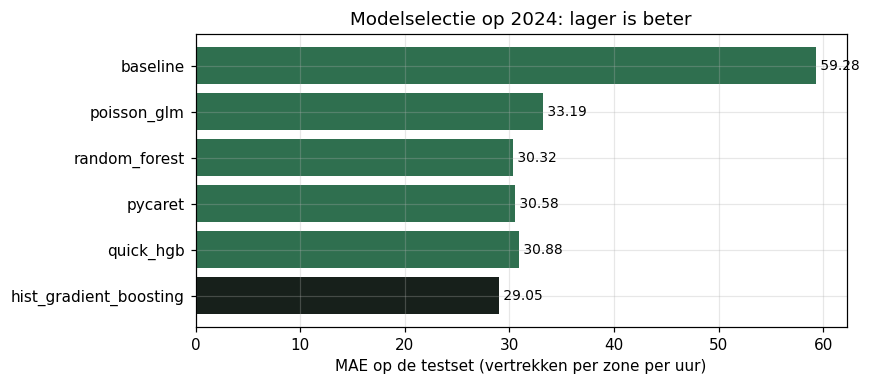

In [31]:
order24 = ["baseline", "poisson_glm", "random_forest", "pycaret", "quick_hgb", "hist_gradient_boosting"]
overview24 = pd.DataFrame(results24).T.loc[order24, ["cv_mae", "mae", "rmse", "r2", "poisson_deviance", "fit_s (5 folds)"]]
display(overview24)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(overview24.index, overview24["mae"].astype(float), color=[INK if n == "hist_gradient_boosting" else GREEN for n in order24])
for i, v in enumerate(overview24["mae"].astype(float)):
    ax.text(v, i, f" {v:.2f}", va="center", fontsize=9)
ax.set(xlabel="MAE op de testset (vertrekken per zone per uur)", title="Modelselectie op 2024: lager is beter")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

### Zijn de verschillen echt?
Twee modellen die 0,5 in MAE verschillen, kunnen even goed zijn: met een andere testweek was de volgorde misschien omgekeerd. We kijken op twee manieren.

**a) Per fold.** Alle scikit-learn-modellen gebruikten exact dezelfde 5 week-folds (`GroupKFold` is deterministisch). Wint het beste model in **elke** fold, dan is het verschil robuust.

In [32]:
fold_table24 = pd.DataFrame({name: cv24[name]["cv_mae"] for name in order24 if cv24.get(name)}, index=[f"fold {i}" for i in range(5)])
display(fold_table24.round(3))
print("Aantal folds (van 5) waarin hist_gradient_boosting beter is dan:",
      {c: int((fold_table24["hist_gradient_boosting"] < fold_table24[c]).sum()) for c in fold_table24 if c != "hist_gradient_boosting"})

,baseline,poisson_glm,random_forest,quick_hgb,hist_gradient_boosting
fold 0,60.574,29.552,27.190,27.832,24.715
fold 1,58.487,31.820,29.863,28.360,26.581
fold 2,69.989,27.661,23.998,25.592,22.729
fold 3,52.398,31.287,29.603,28.042,25.330
fold 4,54.480,31.949,26.341,28.005,25.084


Aantal folds (van 5) waarin hist_gradient_boosting beter is dan: {'baseline': 5, 'poisson_glm': 5, 'random_forest': 5, 'quick_hgb': 5}


**b) Gepaarde block bootstrap op de testset.** We hertrekken 2.000 keer **hele testdagen** (met teruglegging) en berekenen telkens het verschil in MAE tussen twee modellen op exact dezelfde getrokken dagen (**gepaard**). Waarom hele dagen (**block** bootstrap)? Uren van dezelfde dag hangen samen (dezelfde regen, dezelfde feestdag); losse uren hertrekken zou het interval te smal maken.

In [33]:
def paired_bootstrap(pa: pd.DataFrame, pb: pd.DataFrame, n: int = 2000, seed: int = SEED) -> dict:
    """MAE(b) - MAE(a) op de testset, hertrokken per dag; > 0 betekent: a is beter."""
    err = pd.DataFrame({"day": pa["time"].dt.normalize(), "a": (pa["trips"] - pa["pred"]).abs(), "b": (pb["trips"] - pb["pred"]).abs()})
    per_day_ = err.groupby("day")[["a", "b"]].agg(["sum", "count"])
    sa, sb, cnt = per_day_[("a", "sum")].to_numpy(), per_day_[("b", "sum")].to_numpy(), per_day_[("a", "count")].to_numpy()
    idx = np.random.default_rng(seed).integers(0, len(per_day_), size=(n, len(per_day_)))
    diff = sb[idx].sum(1) / cnt[idx].sum(1) - sa[idx].sum(1) / cnt[idx].sum(1)
    return {"MAE-winst": round(float(diff.mean()), 2), "95%-BI": np.round(np.percentile(diff, [2.5, 97.5]), 2).tolist(),
            "P(beter)": round(float((diff > 0).mean()), 3)}


pd.DataFrame({name: paired_bootstrap(preds24["hist_gradient_boosting"], preds24[name]) for name in order24[:-1]}).T

,MAE-winst,95%-BI,P(beter)
baseline,30.16,"[24.73, 35.69]",1.0
poisson_glm,4.14,"[2.4, 5.84]",1.0
random_forest,1.28,"[0.18, 2.52]",0.989
pycaret,1.54,"[0.27, 2.95]",0.995
quick_hgb,1.84,"[1.0, 2.64]",1.0


**Resultaat:**
- de getunede gradient boosting is het beste op **elke** maatstaf: laagste CV-MAE (24,9), laagste test-MAE (29,0), hoogste R² (0,906) en laagste Poisson-deviance;
- **per fold** wint hij in **5 van de 5** folds van elk ander model: de voorsprong is niet het toeval van één week;
- **bootstrap per dag**: tegenover de baseline (+30 vertrekken per uur), het GLM (+4,1) en het snelle model (+1,8) is het verschil overtuigend. Tegenover random forest (+1,3, 95%-BI 0,2 tot 2,5) en PyCaret's Extra Trees (+1,5, BI 0,3 tot 3,0) is het verschil klein: het interval ligt net boven 0. Echt, maar bescheiden.

**Keuze:** **HistGradientBoosting met Poisson-verlies**. Beste fout, klein en snel model (± 5 MB), en het draait met scikit-learn alleen (geen extra pakketten op de server).

## C9. Foutenanalyse van het 2024-model
Waar vergist het gekozen model zich? Eerst per uur van de dag, absoluut en relatief tot de vraag.

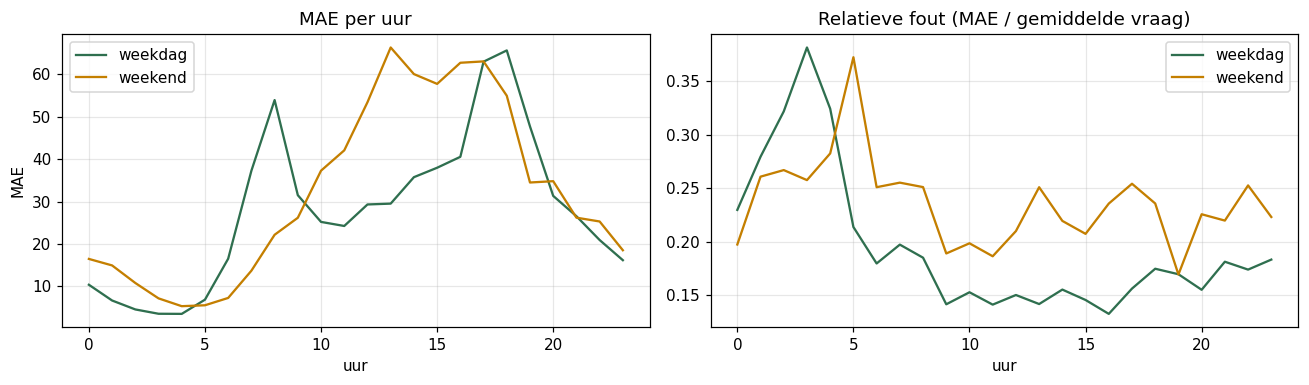

In [34]:
res24 = preds24["hist_gradient_boosting"].merge(t24[["zone", "time", "precipitation_mm", "temperature_c"]], on=["zone", "time"])
res24["error"] = res24["pred"] - res24["trips"]            # > 0: model overschat
res24["abs_error"] = res24["error"].abs()
res24["hour"], res24["weekend"] = res24["time"].dt.hour, res24["time"].dt.dayofweek >= 5
by_hour24 = res24.groupby(["hour", "weekend"])[["abs_error", "trips"]].mean().unstack()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
by_hour24["abs_error"].plot(ax=axes[0], color=[GREEN, ORANGE])
axes[0].set(title="MAE per uur", xlabel="uur", ylabel="MAE"); axes[0].legend(["weekdag", "weekend"])
(by_hour24["abs_error"] / by_hour24["trips"]).plot(ax=axes[1], color=[GREEN, ORANGE])
axes[1].set(title="Relatieve fout (MAE / gemiddelde vraag)", xlabel="uur"); axes[1].legend(["weekdag", "weekend"])
plt.tight_layout()
plt.show()

- In **absolute** termen zit de grootste fout in de **spits** (weekdag 8u en 17–18u) en midden op de dag in het weekend: daar zijn er ook de meeste vertrekken.
- In **relatieve** termen is het omgekeerd: 's nachts (1u–5u) is de fout 25 tot 38% van de vraag. Bij een handvol vertrekken per uur is het toeval groot (Poisson-ruis); dat kan geen enkel model voorspellen, en voor herverdeling is het ook onbelangrijk.
- Het **weekend** is overdag relatief moeilijker (20–25%) dan een weekdag (14–18%): vrijetijdsfietsen hangt meer af van het weer en van plannen die we niet kennen; woon-werkverkeer is regelmatiger.

**Per zone:**

In [35]:
by_zone24 = (res24.groupby("zone").agg(vraag=("trips", "mean"), mae=("abs_error", "mean"), bias=("error", "mean"))
                .assign(relatieve_mae=lambda x: x["mae"] / x["vraag"]).join(zones24["name"]))
by_zone24.sort_values("relatieve_mae", ascending=False).round(2).head(8)

,vraag,mae,bias,relatieve_mae,name
zone,,,,,
29,23.98,5.90,0.62,0.25,rond 36 St & 4 Ave
19,100.87,20.12,6.29,0.20,rond Court St & State St
12,183.12,35.85,10.97,0.20,rond Metropolitan Ave & Bedford Ave
24,82.57,15.99,3.43,0.19,rond Melrose Ave & E 150 St
13,179.88,34.53,8.68,0.19,rond Columbus Ave & W 72 St
25,75.90,14.50,1.99,0.19,rond Parkside Ave & Ocean Ave
23,82.83,15.72,3.53,0.19,rond Franklin St & Dupont St
6,253.43,47.97,14.73,0.19,rond Cleveland Pl & Spring St


De relatieve fout ligt in bijna alle zones rond **19–20%** van de gemiddelde vraag. Alleen de rustigste zone (29, Sunset Park, gemiddeld 24 vertrekken per uur) ligt hoger (25%), door de grotere toevalsruis bij kleine aantallen. Het model werkt dus voor druk en rustig even goed. De **bias** is overal positief: het model **overschat** in elke zone een beetje. Dat komt door de dagen hieronder.

**Per dag:** alle zones en uren opgeteld, vergeleken met de werkelijkheid.

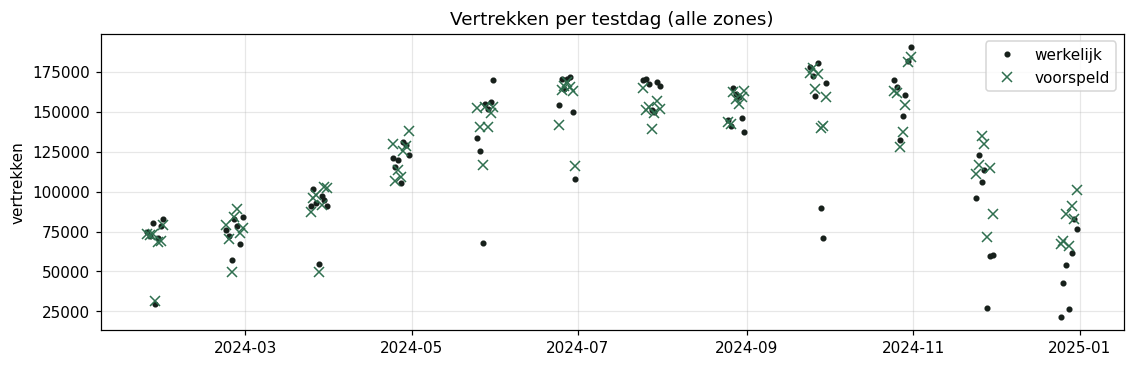

,trips,pred,regen_mm,temp,fout %
time,,,,,
2024-12-25,21562,67519.7,0.0,-3.0,213.1
2024-11-28,27089,71831.3,17.9,7.1,165.2
2024-12-28,26708,66121.5,5.5,4.4,147.6
2024-09-29,71242,140897.9,1.4,17.3,97.8
2024-11-29,59764,114781.8,0.1,4.0,92.1
2024-05-27,67735,116686.9,44.6,19.0,72.3
2024-12-26,42682,69396.8,0.0,-5.1,62.6
2024-12-27,54073,86247.8,0.0,-3.5,59.5


In [36]:
daily24 = res24.groupby(res24["time"].dt.normalize()).agg(trips=("trips", "sum"), pred=("pred", "sum"),
                                                         regen_mm=("precipitation_mm", "mean"), temp=("temperature_c", "mean"))
daily24["regen_mm"] *= 24                                     # gemiddelde mm per uur -> mm per dag
daily24["fout %"] = (daily24["pred"] / daily24["trips"] - 1) * 100
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(daily24.index, daily24["trips"], ".", color=INK, label="werkelijk")
ax.plot(daily24.index, daily24["pred"], "x", color=GREEN, label="voorspeld")
ax.set(title="Vertrekken per testdag (alle zones)", ylabel="vertrekken")
ax.legend()
plt.show()
daily24.reindex(daily24["fout %"].abs().sort_values(ascending=False).index).head(8).round(1)

**Dit is de belangrijkste vondst van de foutenanalyse.** De dagen waarop het model het verst naast zit, zijn bijna allemaal **feestdagen en de dagen errond**:
- **Kerstmis** (25/12): 3 keer te veel voorspeld (+213%). Ook 26, 27 en 28 december worden 60–150% overschat;
- **Thanksgiving** (28/11, met bovendien 18 mm regen, +165%) en de dag erna (Black Friday, 29/11);
- **Memorial Day** (27/5), met 45 mm regen.

**Waarom?** Het model kent alleen een vlag `is_holiday` voor officiële feestdagen. In de trainset zitten daarvan vooral "halve" feestdagen (Columbus Day, Veterans Day, Presidents Day) waarop veel mensen gewoon werken: het leert dus een klein effect (het GLM schatte −17%). Kerstmis en Thanksgiving zijn veel extremer en vallen **allebei in de testset**: in zijn ene trainingsjaar heeft het model er **geen enkel voorbeeld** van gezien. Ook de kerstvakantie en de dag na Thanksgiving zijn geen officiële feestdag, dus het model ziet ze als gewone werkdagen. Dit verklaart ook waarom de testfout hoger is dan de CV-fout.

Daarnaast staat **29 september** in de lijst: half zoveel vertrekken als voorspeld, terwijl de weerdata maar 1,4 mm regen tonen. Waarom het die dag zo rustig was, kunnen we uit deze data niet afleiden: mogelijk regende het lokaal meer dan op het meetpunt van het weermodel.

**Neerslag:** leert het model het regen-effect goed?

In [37]:
res24["regen"] = pd.cut(res24["precipitation_mm"], [-0.01, 0, 0.5, 2, 100], labels=["droog", "≤0,5 mm", "0,5–2 mm", ">2 mm"])
res24.groupby("regen", observed=True).agg(uren=("trips", "size"), werkelijk=("trips", "mean"), voorspeld=("pred", "mean"),
                                         mae=("abs_error", "mean")).round(2)

,uren,werkelijk,voorspeld,mae
regen,,,,
droog,50850,171.90,179.35,27.64
"≤0,5 mm",5970,130.35,131.92,32.33
"0,5–2 mm",2580,89.67,105.93,38.54
>2 mm,1080,88.28,96.15,54.44


Het model leert het regen-effect, maar **onderschat** het: bij 0,5–2 mm per uur voorspelt het gemiddeld 106 vertrekken waar er 90 zijn (18% te veel). De fout bij zware regen (54) is dubbel zo groot als bij droog weer (28). Natte uren zijn zeldzaam (6% van de uren), dus het model heeft er weinig voorbeelden van; bovendien meten we het weer op één punt, terwijl een bui maar een deel van de stad kan raken.

**Welke kenmerken zijn belangrijk? Permutation importance.** We husselen één kolom van de testset door elkaar en meten hoeveel de MAE stijgt (5 herhalingen). Een kenmerk waar het model niets mee doet, kost niets als het gehusseld wordt. Dit is eerlijker dan de impurity importance (C4) en werkt voor elk model.

In [38]:
imp24 = permutation_importance(hgb24, X24t, y24t, scoring="neg_mean_absolute_error", n_repeats=5, random_state=SEED)
pd.Series(imp24.importances_mean, index=F24).sort_values(ascending=False).round(3).rename("MAE-stijging")

hour                98.347
zone                82.477
temperature_c       26.087
weekday             19.859
month               10.260
precipitation_mm     6.322
is_holiday           1.159
is_weekend          -0.037
wind_kmh            -0.247
Name: MAE-stijging, dtype: float64

- **Uur** (+98) en **zone** (+82) zijn veruit het belangrijkst: het dagritme per plaats (A4).
- Dan **temperatuur** (+26), **weekdag** (+20) en **maand** (+10).
- **Neerslag** (+6) lijkt klein, maar het regent zelden; wanneer het regent, maakt het wel een groot verschil.
- **Feestdag** (+1) is klein, omdat er maar een handvol feestdagen in de testset zitten.
- **Wind** en **weekend** dragen **niets** bij (≈ 0). Weekend is overbodig naast `weekday`. Wind zou je kunnen weglaten; het kost niets, maar maakt de API ook niet beter.

### Conclusie deel C
**Gekozen techniek:** HistGradientBoosting met Poisson-verlies, getuned.

| | Baseline | Poisson-GLM | Random forest | PyCaret (Extra Trees) | **HistGB getuned** |
|---|---|---|---|---|---|
| CV-MAE | 59,2 | 30,5 | 27,4 | 26,6 | **24,9** |
| Test-MAE | 59,3 | 33,2 | 30,3 | 30,6 | **29,0** |
| Test-R² | 0,72 | 0,89 | 0,90 | 0,89 | **0,91** |

**Waar het fout ging, en wat zou helpen:** uitzonderlijke dagen (Kerstmis, Thanksgiving en de dagen errond) worden sterk overschat, omdat het model er in één jaar geen voorbeeld van zag. Met **meerdere jaren** data kan het leren van vorige jaren. Dat is de reden voor deel D.

---
# Deel D – Het definitieve model op alle data (2013–2026)
## D0. Wat verandert er?
- **Data:** 2,8 miljoen zone-uren, 13 jaar (`01_cleaning`).
- **Kenmerken:** die van 2024, plus `year` (trend), `active_stations` (aanbod in de zone, `01_cleaning` §12) en `snow_depth_cm` (sneeuw op de grond; toegevoegd na de foutenanalyse, zie D5).
- **Testset:** de laatste 12 maanden (oktober 2025 – september 2026): zo meten we zoals het model gebruikt wordt.
- **Validatie: backtesting** (AWS-hoofdstuk 4). Drie folds: trainen op alle jaren vóór een validatieperiode van 12 maanden, valideren op die periode; de laatste fold valideert op de 12 maanden net vóór de testset. Een model ziet zo nooit de toekomst, net zoals in het echt.

  *Waarom niet meer de `GroupKFold` op weken?* Met 13 jaar data is er een sterke **trend** (het netwerk groeit van 330 naar 2.300 stations). Met willekeurige weken zou het model voor 2019 leren van 2018 én 2020; in de praktijk voorspelt het altijd vooruit.

In [39]:
def backtest_folds(time_: pd.Series, n_folds: int = 3, months: int = 12) -> list:
    """Fold i: trainen op alles vóór een validatieperiode van `months` maanden, valideren op die periode."""
    time_ = pd.to_datetime(time_).reset_index(drop=True)
    end = time_.max() + pd.Timedelta(hours=1)
    folds = []
    for i in range(n_folds, 0, -1):
        val_end = end - pd.DateOffset(months=months * (i - 1))
        val_start = val_end - pd.DateOffset(months=months)
        folds.append((np.flatnonzero(time_ < val_start), np.flatnonzero((time_ >= val_start) & (time_ < val_end))))
    return folds


X, y, _, Xt, yt = train_test(table)
train_time = table.loc[table["split"] == "train", "time"].reset_index(drop=True)
folds = backtest_folds(train_time)
print(f"train: {len(X):,} zone-uren ({train_time.min():%Y-%m} t/m {train_time.max():%Y-%m}) | test: {len(Xt):,} zone-uren "
      f"({table.loc[table['split'] == 'test', 'time'].min():%Y-%m} t/m {table['time'].max():%Y-%m})")
for i, (tr, va) in enumerate(folds):
    print(f"  fold {i}: train {train_time.iloc[tr].min():%Y-%m}–{train_time.iloc[tr].max():%Y-%m} ({len(tr):,}) -> "
          f"valideer {train_time.iloc[va].min():%Y-%m}–{train_time.iloc[va].max():%Y-%m} ({len(va):,})")
results, preds, cv_all = {}, {}, {}


def record_all(name, cv, pred):
    cv_all[name] = cv
    results[name] = {"backtest_mae": cv["cv_mae_mean"] if cv else None, **evaluate(yt, pred)}
    preds[name] = test_frame(table, yt, pred)
    return pd.Series(results[name])


X.head()

train: 2,556,912 zone-uren (2013-06 t/m 2025-09) | test: 262,080 zone-uren (2025-10 t/m 2026-09)
  fold 0: train 2013-06–2022-09 (1,775,088) -> valideer 2022-10–2023-09 (255,504)
  fold 1: train 2013-06–2023-09 (2,030,592) -> valideer 2023-10–2024-09 (263,520)
  fold 2: train 2013-06–2024-09 (2,294,112) -> valideer 2024-10–2025-09 (262,800)


,zone,hour,weekday,month,is_weekend,is_holiday,temperature_c,precipitation_mm,wind_kmh,year,active_stations,snow_depth_cm
0,0,0,5,6,1,0,22.7,0.0,11.2,2013,32,0.0
1,0,1,5,6,1,0,21.9,0.0,10.5,2013,32,0.0
2,0,2,5,6,1,0,21.2,0.0,10.5,2013,32,0.0
3,0,3,5,6,1,0,20.6,0.0,9.7,2013,32,0.0
4,0,4,5,6,1,0,20.1,0.0,9.7,2013,32,0.0


## D1. Baselines op alle data
| Baseline | Voorspelling |
|---|---|
| globaal | het gemiddelde over alle zones en uren |
| per zone × uur × weekend, **alle jaren** | het gemiddelde dagritme van elke zone over 13 jaar |
| per zone × uur × weekend, **laatste 12 maanden** | "hoeveel vertrekken er vorig jaar gemiddeld in deze zone om 8u op een weekdag?" |

In [40]:
base_all = {name: cv_scores(GroupMeanRegressor(**kwargs), X, y, cv=folds)
            for name, kwargs in [("globaal gemiddelde", {"keys": ()}),
                                 ("zone x uur x weekend, alle jaren", {"keys": ("zone", "hour", "is_weekend")}),
                                 ("zone x uur x weekend, laatste 12 maanden", {"keys": ("zone", "hour", "is_weekend"), "recent_months": 12})]}
display(per_fold(base_all).round(1))
reference = GroupMeanRegressor(keys=("zone", "hour", "is_weekend"), recent_months=12)
record_all("baseline", base_all["zone x uur x weekend, laatste 12 maanden"], reference.fit(X, y).predict(Xt))

,cv_mae,fold 0,fold 1,fold 2
globaal gemiddelde,120.0,102.3,121.7,136.0
"zone x uur x weekend, alle jaren",82.1,64.3,85.8,96.1
"zone x uur x weekend, laatste 12 maanden",57.6,47.9,61.2,63.6


backtest_mae         57.6031
mae                  70.9640
rmse                115.4286
r2                    0.6802
poisson_deviance     47.6182
dtype: float64

**Resultaat:**
- het **globale gemiddelde** zit 120 vertrekken per uur naast;
- **zone × uur × weekend over alle jaren** helpt (82), maar minder dan in 2024: het gemiddelde over 13 jaar ligt veel lager dan de vraag van vandaag (het netwerk is 7 keer groter). Een gemiddelde over het verleden onderschat de toekomst systematisch;
- **hetzelfde gemiddelde over alleen de laatste 12 maanden** is duidelijk beter (58): recente data zegt meer over volgend jaar dan oude data. Een eerste aanwijzing dat "meer data" niet vanzelf beter is; het model moet de groei kunnen volgen;
- de fout groeit van fold 0 (48) naar fold 2 (64): er zijn elk jaar meer vertrekken, dus ook grotere absolute fouten.

Op de testset doet de baseline het veel slechter dan in de backtest (**71** tegenover 58, R² 0,68). Hij neemt aan dat volgend jaar hetzelfde is als vorig jaar, terwijl in de testperiode nieuwe stations bijkwamen (vooral in de Bronx en Queens) en de winter koud en sneeuwrijk was (D5).

## D2. Gradient boosting: standaard, 2024-instellingen, opnieuw getuned
Eerst met **standaardinstellingen**, dan met de getunede **instellingen uit 2024** (C6).

In [41]:
record_all("quick_hgb", cv_scores(hgb(), X, y, cv=folds), hgb().fit(X, y).predict(Xt))
cv_2024params = cv_scores(hgb(**params24), X, y, cv=folds)
pred_2024params = hgb(**params24).fit(X, y).predict(Xt)
display(per_fold({"standaard": cv_all["quick_hgb"], "instellingen uit 2024": cv_2024params}).round(3))
pd.DataFrame({"standaard": evaluate(yt, preds["quick_hgb"]["pred"]), "instellingen uit 2024": evaluate(yt, pred_2024params)}).T

,cv_mae,fold 0,fold 1,fold 2
standaard,36.366,31.079,41.218,36.802
instellingen uit 2024,31.993,27.786,38.510,29.684


,mae,rmse,r2,poisson_deviance
standaard,36.0537,63.8321,0.9022,14.9121
instellingen uit 2024,29.0563,53.8429,0.9304,10.6337


**Resultaat:**
- de **standaardinstellingen** volstaan niet meer (backtest 36,4, test 36,1): ze gebruiken maximaal 100 bomen met een learning rate van 0,1, te weinig voor 2,5 miljoen rijen. Toch halveren ze al bijna de fout van de baseline, en ze zijn even goed op de testset als in de backtest: het model ziet het aantal actieve stations en het weer;
- met de **instellingen uit 2024** (tot 1.056 bomen met een kleine learning rate): backtest 32,0, test **29,1**. Dit was de eerste versie van het model op alle data in de API.

### Opnieuw tunen op alle data
Met ± 10 keer meer trainingsdata kan het model complexere bomen gebruiken zonder te overfitten. We zoeken opnieuw, met de waarden uit 2024 in het midden van de zoekruimte; elke combinatie wordt met de **3 backtest-folds** gemeten. Een fit op ± 2,5 miljoen rijen duurt minuten, dus we beperken ons tot 10 combinaties. `HistGradientBoosting` gebruikt bij zoveel data automatisch **early stopping** (10% van de trainrijen als interne validatie): `max_iter` is dus een bovengrens, het model stopt zelf als extra bomen niet meer helpen.

In [42]:
def run_hgb_all():
    search = RandomizedSearchCV(hgb(), {"learning_rate": loguniform(0.02, 0.15), "max_iter": randint(500, 2000),
                                        "max_leaf_nodes": randint(63, 255), "min_samples_leaf": randint(20, 400),
                                        "l2_regularization": loguniform(1e-3, 10)},
                                n_iter=10, cv=folds, scoring="neg_mean_absolute_error", random_state=SEED, n_jobs=1)
    return search_table(search.fit(X, y))


hgb_search_all = cached("hgb_all_data", run_hgb_all)
hgb_search_all.round(3)

,l2_regularization,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf,cv_mae,std_over_folds,fit_seconds
0,0.005,0.023,887,151,335,31.773,4.837,83.629
1,0.179,0.043,1869,115,359,31.808,4.879,133.542
2,0.022,0.027,630,212,328,31.833,4.782,228.416
3,0.053,0.036,1582,232,207,31.892,4.959,148.571
4,0.244,0.049,1738,137,107,31.915,5.029,316.224
5,0.029,0.050,1186,252,70,32.160,4.967,112.653
6,9.308,0.069,1837,84,272,32.162,4.977,103.310
7,7.579,0.107,1305,192,211,32.381,4.962,147.000
8,0.031,0.136,1630,134,208,32.502,4.747,292.053
9,0.034,0.145,1654,113,154,32.640,4.700,95.927


**Resultaat van de zoektocht:** alle tien de combinaties liggen dicht bij elkaar (backtest-MAE 31,8 tot 32,6), terwijl de spreiding over de folds ± 4,8 is. De beste delen hetzelfde patroon als in 2024: een **kleine learning rate** (0,02–0,04) en **grote bomen** (115–212 bladeren). Nieuw is dat ze ook **grote bladeren** willen (`min_samples_leaf` 330–360 in plaats van 18): met meer data kan elk blad op veel meer uren steunen, wat de voorspellingen stabieler maakt. De slechtste combinaties hebben weer een grote learning rate (0,11–0,15).

In [43]:
retuned = best_params(hgb_search_all, ints=("max_iter", "max_leaf_nodes", "min_samples_leaf"), digits=6)
candidates = {"instellingen uit 2024": params24, "opnieuw getuned": retuned}
cand_scores = {"instellingen uit 2024": cv_2024params, "opnieuw getuned": cv_scores(hgb(**retuned), X, y, cv=folds)}
display(per_fold(cand_scores).round(3))
chosen = min(cand_scores, key=lambda k: cand_scores[k]["cv_mae_mean"])
params = candidates[chosen]
final_model = hgb(**params).fit(X, y)
record_all("hist_gradient_boosting", cand_scores[chosen], final_model.predict(Xt))
(MODEL_DIR / "best_params.json").write_text(json.dumps({"source": f"Final/02_analyse_en_modellen ({chosen}, backtest 3 folds)",
                                                         "params": params}, indent=2))
print("Gekozen:", chosen, params)
pd.Series(results["hist_gradient_boosting"])

,cv_mae,fold 0,fold 1,fold 2
instellingen uit 2024,31.993,27.786,38.510,29.684
opnieuw getuned,31.786,27.367,38.497,29.494


Gekozen: opnieuw getuned {'l2_regularization': 0.004809, 'learning_rate': 0.022801, 'max_iter': 887, 'max_leaf_nodes': 151, 'min_samples_leaf': 335}


backtest_mae        31.7859
mae                 28.9411
rmse                53.6342
r2                   0.9309
poisson_deviance    10.6251
dtype: float64

**Resultaat:** de opnieuw getunede instellingen zijn maar een fractie beter dan die uit 2024 (backtest 31,8 tegenover 32,0), maar wel in **alle drie** de folds. Op de testset: **MAE 28,9, R² 0,931**. Dat de winst van het hertunen zo klein is, is op zich een nuttig resultaat: de hyperparameters uit de 2024-studie waren al bijna goed voor 13 jaar data. De grote stappen zaten in de data en de kenmerken (D3–D5).

Het verschil tussen de folds (fold 1, validatie oktober 2023 – september 2024: 38,5; de andere ± 28) komt door de groei: in dat jaar groeide het netwerk het snelst (A1: 2024 +26%), en elke fold leert alleen van de jaren ervoor.

De gekozen instellingen staan in `models/best_params.json`, zodat ook `train.py` ze gebruikt.

**Verder?** Ja, dit is het definitieve model.

## D3. Helpt meer data echt? (leercurve over jaren)
De kernvraag van deze uitbreiding. Hetzelfde model (zelfde hyperparameters), getraind op steeds meer jaren vóór de testperiode, telkens gemeten op dezelfde testset. "1 jaar" is vergelijkbaar met de 2024-studie. Meer data is niet vanzelf beter: het gedrag verandert (e-bikes, corona, nieuwe buurten), en oude jaren kunnen het model naar een verouderd patroon trekken.

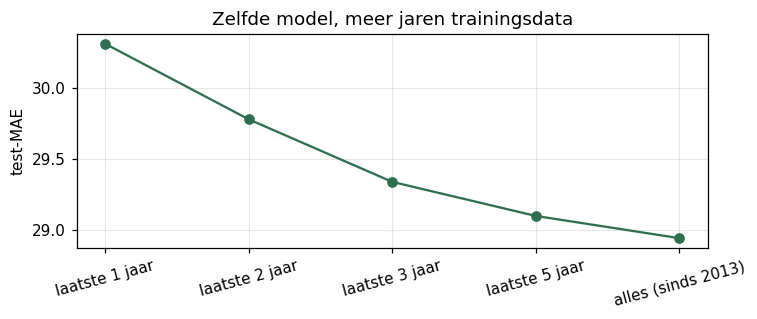

,zone-uren,mae,rmse,r2,poisson_deviance
laatste 1 jaar,262800.0,30.310,55.983,0.925,12.523
laatste 2 jaar,526320.0,29.778,54.782,0.928,11.948
laatste 3 jaar,781824.0,29.337,53.928,0.930,11.562
laatste 5 jaar,1278408.0,29.098,53.707,0.931,11.120
alles (sinds 2013),2556912.0,28.941,53.634,0.931,10.625


In [44]:
test_start = table.loc[table["split"] == "test", "time"].min()
volume = {}
for years in [1, 2, 3, 5, None]:
    since = test_start - pd.DateOffset(years=years) if years else train_time.min()
    keep = (train_time >= since).to_numpy()
    p = hgb(**params).fit(X[keep], y[keep]).predict(Xt)
    volume[f"laatste {years} jaar" if years else "alles (sinds 2013)"] = {"zone-uren": int(keep.sum()), **evaluate(yt, p)}
    if years == 1:
        record_all("hgb_one_year", None, p)
volume = pd.DataFrame(volume).T
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(range(len(volume)), volume["mae"], "o-", color=GREEN)
ax.set(xticks=range(len(volume)), xticklabels=volume.index, ylabel="test-MAE", title="Zelfde model, meer jaren trainingsdata")
plt.setp(ax.get_xticklabels(), rotation=15); plt.tight_layout(); plt.show()
volume.round(3)

**Resultaat:** **ja, meer data helpt**, bij elke stap: 30,3 (1 jaar) → 29,8 → 29,3 → 29,1 → **28,9 (alles)**. De winst neemt af: de oudste jaren (2013–2020, een veel kleiner netwerk zonder e-bikes) voegen nog maar weinig toe, maar schaden ook niet. Dankzij `year` en `active_stations` kan het model het oude gedrag van het nieuwe onderscheiden in plaats van het te middelen.

## D4. Helpen de nieuwe kenmerken? (ablatie)
Bij een **ablatie** laat je één onderdeel weg en meet je opnieuw: wat dan verslechtert, was belangrijk. We laten de drie nieuwe kenmerken één voor één weg, op de backtest én op de testset.

In [45]:
ablation = {}
for name, drop in [("alle kenmerken", []), ("zonder year", ["year"]), ("zonder active_stations", ["active_stations"]),
                   ("zonder snow_depth_cm", ["snow_depth_cm"]),
                   ("zonder alle drie (= kenmerken uit 2024)", ["year", "active_stations", "snow_depth_cm"])]:
    feats = [f for f in FEATURES if f not in drop]
    backtest = cv_scores(hgb(feats, **params), X[feats], y, cv=folds) if drop else cv_all["hist_gradient_boosting"]
    p = hgb(feats, **params).fit(X[feats], y).predict(Xt[feats]) if drop else preds["hist_gradient_boosting"]["pred"].to_numpy()
    ablation[name] = {"backtest_mae": backtest["cv_mae_mean"], **{f"fold {i}": v for i, v in enumerate(backtest["cv_mae"])}, **evaluate(yt, p)}
    if name == "zonder snow_depth_cm":
        preds["zonder_sneeuw"] = test_frame(table, yt, p)
pd.DataFrame(ablation).T.round(3)

,backtest_mae,fold 0,fold 1,fold 2,mae,rmse,r2,poisson_deviance
alle kenmerken,31.786,27.367,38.497,29.494,28.941,53.634,0.931,10.625
zonder year,37.720,30.238,42.372,40.549,35.084,62.946,0.905,14.297
zonder active_stations,32.247,28.059,39.162,29.519,29.212,53.785,0.931,10.848
zonder snow_depth_cm,31.690,27.478,37.885,29.706,30.141,55.079,0.927,11.744
zonder alle drie (= kenmerken uit 2024),74.548,56.278,77.604,89.761,78.962,129.568,0.597,69.017


**Resultaat:**
- **`year` is onmisbaar** (zonder: test 35,1, backtest 37,7). Zonder `year` moet het model 13 jaar groei uitmiddelen. Zonder alle drie de nieuwe kenmerken is het model **onbruikbaar** op alle data (MAE 79, R² 0,60), net als de baseline over alle jaren.
- **`active_stations`** voegt naast `year` weinig maar consistent toe: beter in elke fold. Het helpt vooral waar zones groeien.
- **`snow_depth_cm`** helpt op de testset sterk (30,1 → 28,9) maar **niet in de backtest** (31,7 zonder, 31,8 met; beter in 2 van de 3 folds, slechter in fold 1). Zie D5.

## D5. Een iteratie door de foutenanalyse: sneeuw op de grond
**Aanleiding:** in een eerste versie van de foutenanalyse (deel E, toen nog zonder `snow_depth_cm`) zaten de grootste fouten op **droge dagen ná een sneeuwstorm**: op 26 januari 2026 voorspelde het model 9 keer te veel. Het kende alleen de neerslag van het uur zelf en wist niet dat de straten nog wit lagen.

**Aanpassing:** de sneeuwhoogte (cm sneeuw op de grond, Open-Meteo) als kenmerk. Effect op de dagen na de storm van eind januari 2026:

In [46]:
compare = pd.DataFrame({k: preds[k].groupby(preds[k]["time"].dt.normalize())["pred"].sum() for k in ["zonder_sneeuw", "hist_gradient_boosting"]})
compare["werkelijk"] = preds["hist_gradient_boosting"].groupby(preds["hist_gradient_boosting"]["time"].dt.normalize())["trips"].sum()
snow_day = table.groupby(table["time"].dt.normalize())["snow_depth_cm"].max()
window = compare.loc["2026-01-24":"2026-02-01"].join(snow_day.rename("sneeuw_cm"))
window.assign(**{f"fout % {k}": ((window[k] / window["werkelijk"] - 1) * 100).round(0) for k in ["zonder_sneeuw", "hist_gradient_boosting"]}).round(0)

,zonder_sneeuw,hist_gradient_boosting,werkelijk,sneeuw_cm,fout % zonder_sneeuw,fout % hist_gradient_boosting
time,,,,,,
2026-01-24,36483.0,39698.0,41957,1.0,-13.0,-5.0
2026-01-25,11602.0,10920.0,3051,29.0,280.0,258.0
2026-01-26,58836.0,40737.0,6058,26.0,871.0,572.0
2026-01-27,50745.0,29920.0,16123,21.0,215.0,86.0
2026-01-28,54552.0,35547.0,20656,19.0,164.0,72.0
2026-01-29,51472.0,35570.0,22508,19.0,129.0,58.0
2026-01-30,44181.0,30787.0,20446,19.0,116.0,51.0
2026-01-31,38174.0,26968.0,18436,19.0,107.0,46.0
2026-02-01,28120.0,21828.0,15901,18.0,77.0,37.0


**Resultaat:** de fout op de dagen met sneeuw op straat halveert ruwweg (27 januari: van +215% naar +86%), en de test-MAE daalt van 30,1 naar 28,9.

**Waarom dan niet zichtbaar in de backtest?** Vergelijk de winters (december–februari) van de validatiejaren met de testwinter:

In [47]:
w_hour = table.drop_duplicates("time").set_index("time")[["temperature_c", "snowfall_cm", "snow_depth_cm"]]
w_win = w_hour[w_hour.index.month.isin([12, 1, 2])]
season = pd.Series(w_win.index.year + (w_win.index.month == 12), index=w_win.index).map(lambda yr: f"{yr - 1}–{yr}")
winters = pd.DataFrame({"gem. temperatuur (°C)": w_win.groupby(season)["temperature_c"].mean(),
                        "verse sneeuw (cm)": w_win.groupby(season)["snowfall_cm"].sum(),
                        "dagen met ≥ 5 cm sneeuw op de grond": w_win["snow_depth_cm"].resample("D").max().ge(5)
                            .groupby(season.resample("D").first()).sum(),
                        "max. sneeuwhoogte (cm)": w_win.groupby(season)["snow_depth_cm"].max()})
winters["rol"] = winters.index.map(lambda s: "test" if s == "2025–2026" else
                                   ("validatie (backtest)" if s in ("2022–2023", "2023–2024", "2024–2025") else ""))
winters.loc[winters.index != "2012–2013"].round(1)

,gem. temperatuur (°C),verse sneeuw (cm),dagen met ≥ 5 cm sneeuw op de grond,max. sneeuwhoogte (cm),rol
time,,,,,
2013–2014,-1.6,102.2,54,47.0,
2014–2015,-1.9,60.9,36,35.0,
2015–2016,3.6,17.4,20,27.0,
2016–2017,2.5,18.3,15,17.0,
2017–2018,1.0,42.8,22,16.0,
2018–2019,1.3,16.9,2,6.0,
2019–2020,2.8,25.8,8,10.0,
2020–2021,0.9,39.6,34,30.0,
2021–2022,1.6,36.3,10,15.0,


De validatiewinters (2022–2025) hadden weinig sneeuw op de grond: 1, 22 en 9 dagen met minstens 5 cm, hooguit 14 cm. De testwinter 2025–2026 was samen met 2014–2015 de koudste van de reeks (gemiddeld −1,9 °C), had 41 dagen met sneeuw op de grond (alleen 2013–2014 had er meer) en de grootste sneeuwhoogte van alle jaren (51 cm). Het kenmerk helpt alleen als er sneeuw ligt, en dan veel: in de backtest kon het zijn waarde dus nauwelijks tonen.

**Verder?** **Ja, met een kanttekening.** Het mechanisme is logisch en het effect zit precies op de juiste dagen, maar het is gemeten op één sneeuwrijke winter. Dat onderscheidt het van de lags in C7: die waren in **elke** fold slechter, de sneeuwhoogte is in de backtest neutraal. En de sneeuwhoogte zit in de weersvoorspelling, dus de API kan ze gebruiken.

---
# Deel E – Foutenanalyse van het definitieve model
## E0. Overzicht
- **backtest_mae**: gemiddelde MAE over de 3 backtest-folds;
- **relatieve MAE**: MAE gedeeld door de gemiddelde vraag. Daarmee kunnen we voorzichtig vergelijken met de 2024-studie, die een andere testset had.

In [48]:
order = ["baseline", "quick_hgb", "hgb_one_year", "hist_gradient_boosting"]
overview = pd.DataFrame(results).T.loc[order].astype(float)
overview["relatieve MAE"] = overview["mae"] / yt.mean()
rel24 = results24["hist_gradient_boosting"]["mae"] / y24t.mean()
print(f"Gemiddelde vraag in de testset: {yt.mean():.0f} vertrekken per zone-uur. Ter vergelijking, 2024-studie: "
      f"MAE {results24['hist_gradient_boosting']['mae']:.1f} bij gemiddeld {y24t.mean():.0f} -> relatieve MAE {rel24:.3f}")
display(overview.round(3))
display(pd.DataFrame({n: cv_all[n]["cv_mae"] for n in order if cv_all.get(n)}, index=[f"fold {i}" for i in range(3)]).round(2))
pd.DataFrame({name: paired_bootstrap(preds["hist_gradient_boosting"], preds[name]) for name in order[:-1]}).T

Gemiddelde vraag in de testset: 173 vertrekken per zone-uur. Ter vergelijking, 2024-studie: MAE 29.0 bij gemiddeld 163 -> relatieve MAE 0.178


,backtest_mae,mae,rmse,r2,poisson_deviance,relatieve MAE
baseline,57.603,70.964,115.429,0.680,47.618,0.410
quick_hgb,36.366,36.054,63.832,0.902,14.912,0.208
hgb_one_year,NaN,30.310,55.983,0.925,12.523,0.175
hist_gradient_boosting,31.786,28.941,53.634,0.931,10.625,0.167


,baseline,quick_hgb,hist_gradient_boosting
fold 0,47.93,31.08,27.37
fold 1,61.25,41.22,38.50
fold 2,63.64,36.80,29.49


,MAE-winst,95%-BI,P(beter)
baseline,42.04,"[38.52, 45.71]",1.0
quick_hgb,7.12,"[6.56, 7.67]",1.0
hgb_one_year,1.37,"[0.66, 2.07]",1.0


**Resultaat:**
- het definitieve model is het beste op elke maatstaf: **MAE 28,9, RMSE 53,6, R² 0,931**, Poisson-deviance 10,6. Per backtest-fold is het beter dan het ongetunede model en de baseline, in elke fold;
- de **relatieve fout** is **16,7%** van de gemiddelde vraag (173 vertrekken per zone-uur). In de 2024-studie was dat 17,8%, op een andere testset: voorzichtig vergeleken iets beter, op een moeilijker testjaar (een sneeuwrijke winter);
- **bootstrap per dag**: het definitieve model zit gemiddeld 42 vertrekken per uur dichter bij de werkelijkheid dan de baseline, 7,1 dichter dan het ongetunede model, en **1,4 dichter dan hetzelfde model op één jaar data** (95%-BI 0,7 tot 2,1; in alle 2.000 hertrekkingen beter). De winst van meer data is dus klein, maar echt.

## E1. Per maand, en waar meer data het verschil maakt

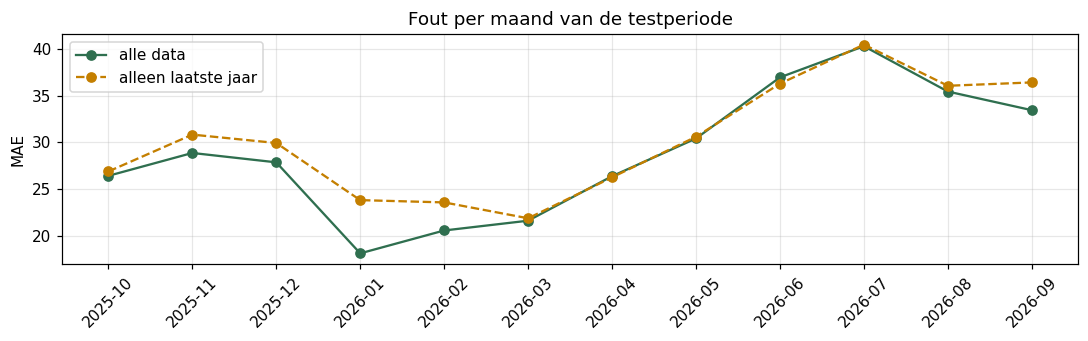

time,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09
vraag,211.9,158.1,93.7,81.3,62.7,131.9,178.6,210.2,249.1,223.6,234.9,230.5
mae,26.4,28.9,27.9,18.1,20.6,21.6,26.4,30.4,37.0,40.3,35.4,33.5
mae_1_jaar,26.9,30.8,29.9,23.8,23.6,21.9,26.3,30.6,36.3,40.5,36.1,36.4


In [49]:
best, one = preds["hist_gradient_boosting"], preds["hgb_one_year"]
res = best.merge(table[["zone", "time", "precipitation_mm", "snow_depth_cm"]], on=["zone", "time"])
res["error"] = res["pred"] - res["trips"]
res["abs_error"] = res["error"].abs()
res["pred_1j"] = one["pred"].to_numpy()
res["abs_error_1j"] = (res["pred_1j"] - res["trips"]).abs()
monthly = res.groupby(res["time"].dt.to_period("M")).agg(vraag=("trips", "mean"), mae=("abs_error", "mean"), mae_1_jaar=("abs_error_1j", "mean"))
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(monthly.index.astype(str), monthly["mae"], "o-", color=GREEN, label="alle data")
ax.plot(monthly.index.astype(str), monthly["mae_1_jaar"], "o--", color=ORANGE, label="alleen laatste jaar")
ax.set(ylabel="MAE", title="Fout per maand van de testperiode"); ax.legend(); plt.setp(ax.get_xticklabels(), rotation=45)
plt.tight_layout(); plt.show()
monthly.round(1).T

**Resultaat:** in 10 van de 12 maanden beter dan het model op één jaar, en het meest in **januari en februari 2026**, de sneeuwmaanden (18,1 tegenover 23,8 en 20,6 tegenover 23,6): 13 jaar bevat meerdere sneeuwwinters (2014, 2015, 2016, 2018, 2021), één jaar bijna geen. In absolute fout is de zomer het moeilijkst (MAE 35–40), daar zijn ook de meeste ritten.

## E2. Feestdagen (de zwakke plek uit 2024)
In de 2024-studie overschatte het model Kerstmis met 213% en Thanksgiving met 165%. Nu heeft het er 12 van elk gezien. Per officiële feestdag in de testperiode, plus de dag na Thanksgiving en de kerstvakantie (24 december – 1 januari):

In [50]:
daily = res.groupby(res["time"].dt.normalize()).agg(trips=("trips", "sum"), pred=("pred", "sum"), pred_1j=("pred_1j", "sum"),
                                                    regen_mm=("precipitation_mm", "mean"), sneeuw_cm=("snow_depth_cm", "max"))
daily["regen_mm"] *= 24
daily["fout %"] = ((daily["pred"] / daily["trips"] - 1) * 100).round(0)
daily["fout % (1 jaar)"] = ((daily["pred_1j"] / daily["trips"] - 1) * 100).round(0)
names = USFederalHolidayCalendar().holidays(daily.index.min(), daily.index.max(), return_name=True)
special = pd.Series(names.to_numpy(), index=names.index)
for h, n in names.items():
    if "Thanksgiving" in n:
        special[h + pd.Timedelta(days=1)] = "dag na Thanksgiving"
for day in pd.date_range(f"{daily.index.min().year}-12-24", f"{daily.index.min().year + 1}-01-01"):
    if day not in special.index:
        special[day] = "kerstvakantie"
special = special.sort_index()
daily.loc[special.index, ["trips", "pred", "fout %", "fout % (1 jaar)"]].assign(dag=special).round(0)

,trips,pred,fout %,fout % (1 jaar),dag
2025-10-13,61079,86293.0,41.0,66.0,Columbus Day
2025-11-11,96690,46865.0,-52.0,-63.0,Veterans Day
2025-11-27,45245,47399.0,5.0,-22.0,Thanksgiving Day
2025-11-28,53762,90149.0,68.0,40.0,dag na Thanksgiving
2025-12-24,50826,103061.0,103.0,90.0,kerstvakantie
2025-12-25,25529,32231.0,26.0,38.0,Christmas Day
2025-12-26,30140,66761.0,122.0,145.0,kerstvakantie
2025-12-27,12864,38266.0,197.0,143.0,kerstvakantie
2025-12-28,23486,31136.0,33.0,28.0,kerstvakantie
2025-12-29,41157,69355.0,69.0,36.0,kerstvakantie


**Resultaat:**
- de grote feestdagen gaan nu goed: **Thanksgiving +5%** (één jaar data: −22%; 2024-studie: +165%), **Kerstmis +26%** (2024-studie: +213%), **Nieuwjaar −4%**, **Memorial Day +11%**, **Labor Day −7%**, Juneteenth −9%;
- matig: **Martin Luther King Day −16%**, **Presidents Day +20%** en **4 juli** (dit jaar gevierd op vrijdag 3 juli) **+23%**;
- fout: **Columbus Day +41%** (bovendien een regendag) en **Veterans Day −52%**: op beide dagen werken veel New Yorkers gewoon, maar het model leerde één effect voor alle feestdagen samen. Eén vlag `is_holiday` is dus te grof;
- wat ook nog misgaat, zijn de dagen **rond** de feestdagen die zelf geen feestdag zijn: de dag na Thanksgiving (+68%), kerstavond (+103%) en de week tot Nieuwjaar (+33% tot +197%). Het model kent daar geen "vakantie" en verwacht gewone werkdagen.

**Niet gedaan, wel een volgende stap:** aparte kenmerken per soort feestdag, en een kenmerk voor vakantieperiodes.

## E3. De grootste dagfouten, neerslag, zones en uren

In [51]:
display(daily.reindex(daily["fout %"].abs().sort_values(ascending=False).index).head(10)[["trips", "pred", "fout %", "fout % (1 jaar)", "regen_mm", "sneeuw_cm"]].round(1))
res["regen"] = pd.cut(res["precipitation_mm"], [-0.01, 0, 0.5, 2, 100], labels=["droog", "≤0,5 mm", "0,5–2 mm", ">2 mm"])
res.groupby("regen", observed=True).agg(uren=("trips", "size"), werkelijk=("trips", "mean"), voorspeld=("pred", "mean"),
                                        voorspeld_1_jaar=("pred_1j", "mean"), mae=("abs_error", "mean"), mae_1_jaar=("abs_error_1j", "mean")).round(1)

,trips,pred,fout %,fout % (1 jaar),regen_mm,sneeuw_cm
time,,,,,,
2026-01-26,6058,40737.2,572.0,805.0,0.4,26.0
2026-01-25,3051,10919.6,258.0,515.0,33.8,29.0
2025-12-27,12864,38265.6,197.0,143.0,5.3,10.0
2026-02-24,13119,32950.5,151.0,345.0,0.0,51.0
2025-12-26,30140,66761.3,122.0,145.0,9.0,5.0
2025-12-24,50826,103060.7,103.0,90.0,0.0,1.0
2026-01-27,16123,29920.2,86.0,205.0,0.1,21.0
2026-02-22,19029,34008.7,79.0,82.0,13.8,8.0
2025-12-30,49286,88267.2,79.0,70.0,0.0,0.0


,uren,werkelijk,voorspeld,voorspeld_1_jaar,mae,mae_1_jaar
regen,,,,,,
droog,221160,177.3,174.1,174.0,26.6,27.5
"≤0,5 mm",23130,182.7,179.0,181.1,42.4,44.1
"0,5–2 mm",12180,121.6,124.5,122.7,40.4,46.5
>2 mm,5610,76.6,102.1,107.4,42.6,47.2


- De grootste dagfouten zitten in twee groepen: **na een sneeuwstorm** (25–27 januari 2026: 26–29 cm sneeuw; 24 februari 2026: 51 cm, de dag na de sluiting) en de **kerstvakantie**. De sneeuwhoogte helpt al veel (D5), maar op de dag zelf of vlak na zware sneeuw blijft het model te optimistisch: het weet niet of de straten al geruimd zijn of het systeem gedeeltelijk dicht is.
- Bij droog weer en lichte neerslag klopt het gemiddelde bijna precies (177 tegen 174). Bij **zware regen (> 2 mm/u)** overschat het model nog steeds (102 voorspeld, 77 werkelijk), zoals in 2024; het model op alle data doet het daar wel beter dan dat op één jaar (MAE 42,6 tegenover 47,3). Zware buien blijven zeldzaam (2% van de uren), en het weer wordt op één punt gemeten.

,vraag,mae,bias,relatieve_mae,name,active_stations
zone,,,,,,
28,49.74,13.19,-7.22,0.27,rond 81 St & 34 Ave,174
29,31.71,7.67,0.29,0.24,rond 36 St & 4 Ave,101
27,58.84,13.95,-7.97,0.24,rond E Fordham Rd & Webster Ave,190
17,134.68,26.89,-11.37,0.20,rond Franklin St & Dupont St,37
24,72.13,13.99,-3.70,0.19,rond Parkside Ave & Ocean Ave,98
13,162.12,30.34,7.73,0.19,rond Columbus Ave & W 72 St,29


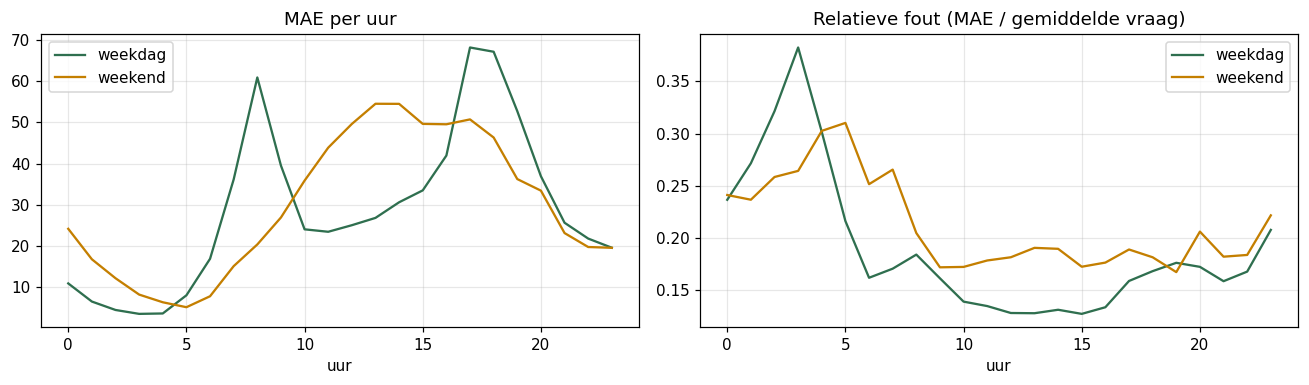

In [52]:
by_zone = (res.groupby("zone").agg(vraag=("trips", "mean"), mae=("abs_error", "mean"), bias=("error", "mean"))
             .assign(relatieve_mae=lambda x: x["mae"] / x["vraag"]).join(zones[["name", "active_stations"]]))
display(by_zone.sort_values("relatieve_mae", ascending=False).round(2).head(6))
res["hour"], res["weekend"] = res["time"].dt.hour, res["time"].dt.dayofweek >= 5
by_hour = res.groupby(["hour", "weekend"])[["abs_error", "trips"]].mean().unstack()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
by_hour["abs_error"].plot(ax=axes[0], color=[GREEN, ORANGE])
axes[0].set(title="MAE per uur", xlabel="uur"); axes[0].legend(["weekdag", "weekend"])
(by_hour["abs_error"] / by_hour["trips"]).plot(ax=axes[1], color=[GREEN, ORANGE])
axes[1].set(title="Relatieve fout (MAE / gemiddelde vraag)", xlabel="uur"); axes[1].legend(["weekdag", "weekend"])
plt.tight_layout()
plt.show()

- **Per zone**: de grootste relatieve fout zit in de zones die het snelst **groeien**: 28 (Jackson Heights/Corona, Queens) en 27 (Fordham, de Bronx), elk met 170–190 stations, en de rustigste zone 29 (Sunset Park). In 27 en 28 **onderschat** het model de vraag (bias −7 à −8): nieuwe stations worden steeds beter gebruikt, en dat volgt het model met wat vertraging.
- **Per uur**: hetzelfde patroon als in 2024. In absolute zin zitten de grootste fouten in de spits (8u en 17–18u op weekdagen) en midden op de dag in het weekend; relatief is de nacht het moeilijkst (weinig ritten, veel toeval). Overdag is de relatieve fout op weekdagen 13–17%, in het weekend 17–19%.

## E4. Welke kenmerken gebruikt het model? (permutation importance)
Op een steekproef van 200.000 testuren (de volledige testset is groot en het resultaat verandert er nauwelijks door), 3 herhalingen.

In [53]:
sample = Xt.sample(200_000, random_state=SEED)
imp = permutation_importance(final_model, sample, yt.loc[sample.index], scoring="neg_mean_absolute_error", n_repeats=3, random_state=SEED)
pd.Series(imp.importances_mean, index=FEATURES).sort_values(ascending=False).round(2).rename("MAE-stijging")

hour                101.92
zone                 93.84
temperature_c        38.60
weekday              20.38
precipitation_mm      8.24
month                 7.07
snow_depth_cm         4.78
active_stations       4.30
is_holiday            1.82
wind_kmh              0.61
is_weekend            0.41
year                  0.00
Name: MAE-stijging, dtype: float64

**Resultaat:** uur en zone blijven veruit het belangrijkst, dan temperatuur en weekdag, net als in 2024; sneeuwhoogte (+4,8) en actieve stations (+4,3) dragen duidelijk bij.

Opvallend: **`year` scoort 0**, terwijl het model zonder `year` veel slechter is (D4). Geen tegenspraak: permutation importance husselt een kolom **binnen de testset**, en daarin is het jaar bijna overal 2025 of 2026. `year` is nodig om bij het **trainen** de jaren uit elkaar te houden, niet om binnen één testjaar te onderscheiden. Een goede les: permutation importance meet "wat helpt binnen deze testset", niet "wat had het model nodig om te leren".

---
# Deel F – Deployment
## F1. Van notebook naar API
```
dit notebook (of train.py)  ->  deploy/citi_bike_demand/model.pkl  ->  merge naar main
  -> GitHub Actions (deploy-api.yml): testen, kopiëren naar de Oracle VM, herstarten, rollback als de API niet start
  -> api_smoke_test.yml (na elke deploy en dagelijks)
```
Hieronder gebeurt wat `train.py` doet (dezelfde stappen, zodat het model ook zonder notebook hertraind kan worden):
1. het model **eerlijk meten**: trainen op het verleden, testen op de laatste 12 maanden (dat is het model van D2);
2. **kwaliteitscontrole**: weigeren als het meer dan 2% slechter is dan het model dat er nu staat (alleen als dat op dezelfde testperiode gemeten werd, anders zijn de cijfers niet vergelijkbaar);
3. het model **opnieuw fitten op alle uren** (ook de laatste 12 maanden: de meest recente data is de nuttigste voor de toekomst);
4. een **bundle** wegschrijven met **joblib**: model, kenmerken, hyperparameters, metrics, testperiode, zones en beperkingen. De API leest die bundle.

De **API** (FastAPI, `/citi_bike_demand`) berekent dezelfde kenmerken als `make_features` hierboven (gecontroleerd door `test_features.py`), met het **huidige** aantal actieve stations per zone. De **webpagina** (`citi_bike_demand.html`) haalt het weer (ook de sneeuwhoogte) automatisch op bij Open-Meteo en toont de verwachte vertrekken per uur voor een gekozen zone en dag, met scenario's (droog / regen).

In [54]:
TOLERANCE = 0.02
is_test = (table["split"] == "test").to_numpy()
test_period = f"{table.loc[is_test, 'time'].min():%Y-%m-%d} t/m {table.loc[is_test, 'time'].max():%Y-%m-%d}"
metrics = results["hist_gradient_boosting"].copy()
metrics.pop("backtest_mae")
print("Hold-out:", metrics)
write = True
if DEPLOY_MODEL.exists():
    current = joblib.load(DEPLOY_MODEL)
    if current.get("test_period") == test_period:
        limit = current["metrics"]["mae"] * (1 + TOLERANCE)
        print(f"Huidig model: MAE {current['metrics']['mae']:.4f}; nieuw: {metrics['mae']:.4f} (grens {limit:.4f})")
        write = metrics["mae"] <= limit
    else:
        print(f"Huidig model werd op een andere testperiode gemeten ({current.get('test_period', 'onbekend')}): geen vergelijking.")
if write:
    deployed = hgb(**params).fit(make_features(table), table["trips"])
    first_t, last_t = table["time"].min(), table["time"].max()
    bundle = {"model": deployed, "model_name": "HistGradientBoosting (Poisson)", "target": "vertrekken per zone per uur",
              "features": FEATURES, "params": params, "metrics": metrics, "test_period": test_period,
              "metrics_note": f"gemeten op {test_period} met een model getraind op alle uren daarvoor; "
                              "het gedeployde model is daarna op alle uren hertraind",
              "trained_on": f"{first_t:%Y-%m-%d} t/m {last_t:%Y-%m-%d}",
              "zones": json.loads((DATA_DIR / "zones.json").read_text(encoding="utf-8")),
              "trained_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
              "limitations": ("Geschat gemiddelde, geen garantie. Het model kent geen evenementen, wegenwerken, "
                              "stationsstoringen of het aantal beschikbare fietsen; de vraag is gemeten als gerealiseerde "
                              f"vertrekken (een leeg station telt als 0 vraag). Getraind op {first_t:%Y}-{last_t:%Y}; voor "
                              "nieuwe voorspellingen gebruikt het het huidige aantal actieve stations per zone.")}
    joblib.dump(bundle, DEPLOY_MODEL, compress=3)
    (MODEL_DIR / "metrics").mkdir(parents=True, exist_ok=True)
    (MODEL_DIR / "metrics" / "deployed.json").write_text(json.dumps({"model": bundle["model_name"], "params": params, **metrics,
                                                                      "test_period": test_period, "trained_at_utc": bundle["trained_at_utc"]},
                                                                     indent=2), encoding="utf-8")
    print(f"Bundle geschreven naar {DEPLOY_MODEL.relative_to(KOBE.parent.parent)} ({DEPLOY_MODEL.stat().st_size / 1e6:.1f} MB)")
else:
    print("Nieuw model is slechter dan het huidige: niet weggeschreven.")

Hold-out: {'mae': 28.9411, 'rmse': 53.6342, 'r2': 0.9309, 'poisson_deviance': 10.6251}
Huidig model: MAE 28.9411; nieuw: 28.9411 (grens 29.5199)


Bundle geschreven naar deploy\citi_bike_demand\model.pkl (7.1 MB)


**Controle:** de bundle opnieuw laden, zoals de API dat doet, en een voorspelling maken voor de drukste zone op een droge dinsdag in oktober, om 8u en om 3u, en bij regen.

In [55]:
bundle = joblib.load(DEPLOY_MODEL)
latest_active = {z["zone"]: z["active_stations"] for z in bundle["zones"]}
probe = pd.DataFrame({"zone": 0, "time": pd.to_datetime(["2026-10-13 08:00", "2026-10-13 03:00", "2026-10-13 08:00"]),
                      "temperature_c": 15.0, "precipitation_mm": [0.0, 0.0, 3.0], "wind_kmh": 10.0, "snow_depth_cm": 0.0})
probe["active_stations"] = probe["zone"].map(latest_active)
print("Kenmerken in de bundle == FEATURES:", bundle["features"] == FEATURES)
probe.assign(voorspelling=bundle["model"].predict(make_features(probe, bundle["features"])).round(0))[["time", "precipitation_mm", "voorspelling"]]

Kenmerken in de bundle == FEATURES: True


,time,precipitation_mm,voorspelling
0,2026-10-13 08:00:00,0.0,1197.0
1,2026-10-13 03:00:00,0.0,23.0
2,2026-10-13 08:00:00,3.0,472.0


Het model geeft logische antwoorden: veel vertrekken om 8u, bijna niets om 3u, en duidelijk minder bij regen.

---
# Deel G – Conclusie
## Wat we probeerden, wat het gaf, en waarom we wel of niet verder gingen
| Poging | Waarom | Resultaat | Verder? |
|---|---|---|---|
| Baseline (gemiddelde per zone × uur × weekend) | weten wat "goed" is | 2024: MAE 59; alle data: 71 | als lat |
| Snel model (HistGB, standaard) | vroeg een model voor de API | 2024: MAE 30,9 | ja, als vertrekpunt |
| Poisson-GLM met interactie | uitlegbare effecten | MAE 33,2; regen −30%/mm, feestdag −17%, optimum 29 °C | nee als voorspeller (mist interacties), wel voor uitleg |
| Random forest (2 zoekrondes) | bagging, interacties | MAE 30,3; eerste zoekronde maakte het slechter | nee: minder goed dan boosting, groot model |
| PyCaret (AutoML) | onafhankelijke controle | Extra Trees 30,6; lineaire modellen 97 | nee: geen beter model |
| **Gradient boosting (Poisson), getuned** | **boosting, Poisson, klein en snel** | **2024: MAE 29,0**, beste in 5/5 folds | **ja** |
| Lags (recente vraag) | autocorrelatie | test beter, CV slechter in elke fold | nee: misleidend, en niet bruikbaar zonder live data |
| **Alle data (2013–2026)** | zeldzame dagen leren | **MAE 28,9, R² 0,931**; feestdagen grotendeels goed | **ja (gedeployd)** |
| `year`, `active_stations` | groei van het netwerk | zonder: onbruikbaar (MAE 79) | ja |
| `snow_depth_cm` | grootste fouten na sneeuwstormen | test 30,1 → 28,9; backtest neutraal | ja, met kanttekening |
| Hertunen op alle data | meer data, andere optimale instellingen | backtest 32,0 → 31,8 | ja (kleine winst) |

## Wat het model kan, en wat niet
- Het voorspelt de vraag per zone per uur met een gemiddelde fout van ± 17%, en vangt het dagritme, het seizoen, het weer, de grote feestdagen en de groei van het netwerk.
- Het vergist zich vooral in de **kerstvakantie**, op **feestdagen waarop veel mensen werken** (Columbus Day, Veterans Day), **vlak na zware sneeuw**, bij **zware buien**, en in **snelgroeiende zones**.
- **Beperkingen:** de data bevat gerealiseerde ritten, geen echte vraag (een leeg station telt als 0); het weer komt van één punt in de stad; evenementen en stationsstoringen ontbreken.
- **Volgende stappen:** kenmerken voor vakantieperiodes en per soort feestdag, weer per zone, en (met een live koppeling) de beschikbaarheid van fietsen.